
# Lab 3: Supervised Machine Learning — Classification and Regression

**Course:** Artificial Intelligence Algorithms and Mathematics  
**Student Name:** Ubaid Ullah  
**Student ID:** 9110715  
**Section:** 1  

---

## 1. Introduction

This lab explores two supervised machine learning techniques to solve real-world prediction problems using Python and scikit-learn.

**Part A — Credit Card Fraud Detection**

The objective is to develop a Logistic Regression classification model that identifies potentially fraudulent credit card transactions. The model will be trained on 70% of the data and tested on the remaining 30%.

**Part B — Insurance Cost Prediction**

The objective is to develop a Linear Regression model that predicts individual medical insurance charges based on demographic and lifestyle characteristics. A 70/30 train-test split will also be applied.

## 2. Learning Objectives

By completing this lab, the following tasks will be demonstrated:

1. Load and explore real-world datasets using pandas.
2. Identify missing values, duplicates, and relevant data characteristics.
3. Perform appropriate preprocessing and exploratory data analysis (EDA).
4. Split each dataset into 70% training and 30% testing data.
5. Train Logistic Regression and Linear Regression models.
6. Evaluate model performance using suitable classification and regression metrics.
7. Visualize results and interpret the models' predictive performance.
8. Summarize key findings, limitations, and possible improvements.

## 3. Datasets

**Dataset A: Credit Card Fraud Detection**
- Source: Kaggle — Machine Learning Group, ULB
- File: `creditcard.csv`
- Target variable: `Class`
- Problem type: Binary Classification

**Dataset B: Medical Cost Personal Dataset**
- Source: Kaggle — Mirichoi
- File: `insurance.csv`
- Target variable: `charges`
- Problem type: Regression

Both datasets will be analyzed independently using the algorithms specified in the lab instructions.



## 4. Python Libraries and Environment Setup

This lab uses Python libraries for data manipulation, exploratory data analysis, visualization, and machine learning.

The main libraries include:

- **pandas:** Loading, cleaning, and analyzing datasets.
- **NumPy:** Numerical calculations and array operations.
- **Matplotlib:** Creating graphs and visualizations.
- **Seaborn:** Statistical visualizations and data exploration.
- **scikit-learn:** Data preprocessing, model training, and performance evaluation.

Additional scikit-learn components will be imported as needed for each prediction task.


In [1]:

# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Verify that the libraries are available
print("All required data analysis libraries imported successfully.")


All required data analysis libraries imported successfully.



---

## 5. Part A — Credit Card Fraud Detection

### 5.1 Dataset Loading and Initial Inspection

The Credit Card Fraud Detection dataset contains credit card transactions labeled as legitimate or fraudulent.

The target variable is `Class`:
- **0:** Legitimate transaction
- **1:** Fraudulent transaction

The dataset also contains `Time`, `Amount`, and anonymized numerical features (`V1` through `V28`).

In this section, the dataset is loaded using pandas, and its dimensions, column names, and first five records are examined to understand its structure before preprocessing.


In [2]:

# Load the credit card fraud dataset
creditcard_df = pd.read_csv("creditcard.csv")

# Display the dataset dimensions
print("Dataset Shape (Rows, Columns):", creditcard_df.shape)

# Display column names
print("\nColumn Names:")
print(creditcard_df.columns.tolist())

# Display the first five records
print("\nFirst Five Records:")
display(creditcard_df.head())


Dataset Shape (Rows, Columns): (284807, 31)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

First Five Records:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



### 5.2 Data Quality Assessment

Before training the classification model, the dataset is examined for potential data quality issues.

The following checks are performed:

1. **Data types:** Verify whether the features contain numerical or categorical values.
2. **Missing values:** Identify any incomplete records that may require treatment.
3. **Duplicate records:** Identify repeated transactions that could affect model evaluation.

These checks help determine which preprocessing steps are necessary. Any duplicate removal will be considered carefully because fraudulent transactions are rare.


In [3]:

# Examine dataset information and data types
print("Dataset Information:")
creditcard_df.info()

# Check missing values
print("\nMissing Values by Column:")
missing_values = creditcard_df.isnull().sum()
display(missing_values.to_frame(name="Missing Values"))

print("Total Missing Values:", missing_values.sum())

# Check duplicate records
duplicate_count = creditcard_df.duplicated().sum()
print("\nTotal Duplicate Records:", duplicate_count)


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total Missing Values: 0

Total Duplicate Records: 1081



#### 5.2.1 Data Quality Findings

The initial data quality assessment produced the following findings:

- **Dataset size:** 284,807 transactions and 31 columns.
- **Data types:** 30 columns contain `float64` values, while the target variable `Class` contains `int64` values.
- **Missing values:** No missing values were detected in any column. Therefore, missing-value imputation is unnecessary.
- **Duplicate records:** 1,081 duplicate rows were identified, representing approximately 0.38% of the dataset.
- **Memory usage:** Approximately 67.4 MB.

**Interpretation:**

The dataset is suitable for further analysis because all features are numerical and there are no missing values. However, the presence of 1,081 duplicate records requires additional investigation.

Duplicate transactions will not be removed automatically because their distribution across legitimate and fraudulent classes must first be examined. This is particularly important for fraud detection, where fraudulent transactions are relatively rare.

The next step is to analyze the target variable distribution and investigate duplicate records by transaction class.



### 5.3 Class Distribution and Duplicate Analysis

Understanding the distribution of the target variable is essential for credit card fraud detection.

This analysis examines:

1. The number and percentage of legitimate and fraudulent transactions.
2. The distribution of duplicate records across both classes.

These findings will help determine whether class imbalance requires special consideration during model training and evaluation.


In [4]:

# Count transactions in each class
class_counts = creditcard_df["Class"].value_counts().sort_index()

# Calculate class percentages
class_percentages = (
    creditcard_df["Class"].value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Transaction Count": class_counts,
    "Percentage (%)": class_percentages.round(4)
})

class_distribution.index = ["Legitimate (0)", "Fraudulent (1)"]

print("Transaction Class Distribution:")
display(class_distribution)

# Investigate duplicate records by class
duplicate_mask = creditcard_df.duplicated()

print("\nDuplicate Records by Class:")
print(
    creditcard_df.loc[duplicate_mask, "Class"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
)

print("\nTotal Duplicate Records:", duplicate_mask.sum())


Transaction Class Distribution:


,Transaction Count,Percentage (%)
Legitimate (0),284315,99.8273
Fraudulent (1),492,0.1727



Duplicate Records by Class:
Class
Legitimate    1062
Fraudulent      19
Name: count, dtype: int64

Total Duplicate Records: 1081



#### 5.3.1 Class Distribution and Duplicate Analysis Findings

The dataset contains 284,807 credit card transactions, distributed as follows:

| Transaction Type | Count | Percentage |
|---|---:|---:|
| Legitimate (Class 0) | 284,315 | 99.8273% |
| Fraudulent (Class 1) | 492 | 0.1727% |

**Key Findings:**

1. **Severe Class Imbalance:** Only 0.1727% of transactions are fraudulent. Therefore, classification accuracy alone may be misleading. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy without detecting any fraud.

2. **Duplicate Records:** A total of 1,081 duplicate records were identified, including 1,062 legitimate and 19 fraudulent records.

3. **Preprocessing Decision:** Exact duplicate rows will be removed before splitting the dataset to reduce the possibility of identical observations appearing in both training and testing sets. However, because transaction identifiers are unavailable, we cannot confirm whether every identical row represents a repeated recording rather than a distinct transaction.

4. **Model Evaluation:** In addition to accuracy, precision, recall, F1-score, and the confusion matrix will be used to assess fraud detection performance.

5. **Train-Test Strategy:** A stratified 70/30 train-test split will be applied to preserve approximately the same fraud proportion in both datasets.

These decisions aim to provide a more reliable evaluation of the Logistic Regression classification model.


In [5]:

# Remove exact duplicate rows before train-test splitting
creditcard_clean_df = creditcard_df.drop_duplicates().copy()

# Compare the original and cleaned datasets
print("Original Dataset Shape:", creditcard_df.shape)
print("Cleaned Dataset Shape:", creditcard_clean_df.shape)

print("\nRecords Removed:",
      len(creditcard_df) - len(creditcard_clean_df))

# Verify that no duplicate rows remain
print("Remaining Duplicates:",
      creditcard_clean_df.duplicated().sum())

# Examine the class distribution after cleaning
print("\nClass Distribution After Cleaning:")
display(
    creditcard_clean_df["Class"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
    .to_frame(name="Transaction Count")
)


Original Dataset Shape: (284807, 31)
Cleaned Dataset Shape: (283726, 31)

Records Removed: 1081
Remaining Duplicates: 0

Class Distribution After Cleaning:


,Transaction Count
Class,
Legitimate,283253
Fraudulent,473



### 5.4 Visualization of Class Distribution

The distribution of legitimate and fraudulent transactions is visualized using a bar chart.

Because the dataset is highly imbalanced, a logarithmic scale is applied to the vertical axis so that both classes remain visible.

The chart displays transaction counts and percentages to illustrate the difference between the majority and minority classes after duplicate removal.


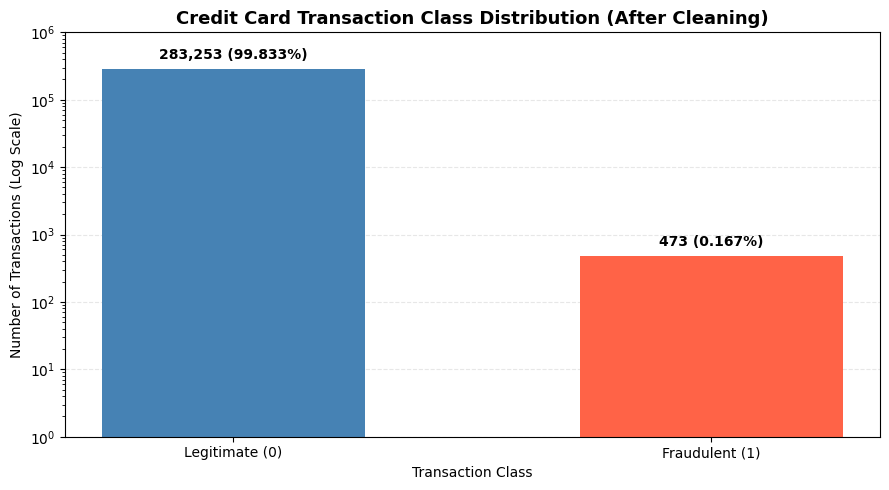

In [6]:

# Calculate class counts and percentages after cleaning
class_counts_clean = (
    creditcard_clean_df["Class"].value_counts().sort_index()
)

class_percentages_clean = (
    class_counts_clean / class_counts_clean.sum() * 100
)

# Define descriptive labels
class_labels = ["Legitimate (0)", "Fraudulent (1)"]

# Create the class distribution visualization
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    class_labels,
    class_counts_clean.values,
    color=["steelblue", "tomato"],
    width=0.55
)

# Use logarithmic scaling to highlight the minority class
ax.set_yscale("log")

# Add transaction counts and percentages above each bar
for bar, count, percentage in zip(
    bars, class_counts_clean.values, class_percentages_clean.values
):
    ax.annotate(
        f"{count:,} ({percentage:.3f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, count),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# Add descriptive labels
ax.set_title(
    "Credit Card Transaction Class Distribution (After Cleaning)",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions (Log Scale)")
ax.set_ylim(1, 1_000_000)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 5.4.1 Visualization Findings

The class distribution visualization confirms that legitimate transactions significantly outnumber fraudulent transactions.

After removing exact duplicates, the dataset contains 283,253 legitimate transactions and only 473 fraudulent transactions.

This severe class imbalance presents a challenge for Logistic Regression because a model may favor the majority class and still achieve high overall accuracy.

Therefore, the dataset will be divided using stratified sampling, and performance evaluation will include precision, recall, F1-score, and a confusion matrix in addition to accuracy.



### 5.5 Descriptive Statistics and Feature Analysis

Descriptive statistics help identify the central tendency, variability, and range of numerical features.

The dataset contains:
- **Time:** Seconds elapsed between each transaction and the first transaction in the dataset.
- **Amount:** Transaction amount.
- **V1–V28:** Anonymized numerical features obtained through Principal Component Analysis (PCA).
- **Class:** Binary target variable (0 = legitimate, 1 = fraudulent).

This analysis focuses on the `Time` and `Amount` features and compares transaction amounts across legitimate and fraudulent classes.

The results will help identify potential differences between transaction groups and inform preprocessing decisions.


In [7]:

# Descriptive statistics for Time and Amount
print("Descriptive Statistics for Time and Amount:")

display(
    creditcard_clean_df[["Time", "Amount"]]
    .describe()
    .T
    .round(2)
)

# Compare transaction amounts by class
print("\nTransaction Amount Statistics by Class:")

amount_by_class = (
    creditcard_clean_df
    .groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

amount_by_class.index = [
    "Legitimate (0)",
    "Fraudulent (1)"
]

display(amount_by_class)

# Check transactions with zero amount
zero_amount_count = (
    creditcard_clean_df["Amount"] == 0
).sum()

print("\nTransactions with Zero Amount:", zero_amount_count)


Descriptive Statistics for Time and Amount:


,count,mean,std,min,25%,50%,75%,max
Time,283726.0,94811.08,47481.05,0.0,54204.75,84692.5,139298.00,172792.00
Amount,283726.0,88.47,250.40,0.0,5.60,22.0,77.51,25691.16



Transaction Amount Statistics by Class:


,count,mean,median,std,min,max
Legitimate (0),283253,88.41,22.00,250.38,0.0,25691.16
Fraudulent (1),473,123.87,9.82,260.21,0.0,2125.87



Transactions with Zero Amount: 1808



#### 5.5.1 Descriptive Statistics Findings

The descriptive statistical analysis of the cleaned dataset revealed the following:

**1. Transaction Time**
- The average transaction time is 94,811.08 seconds.
- Transaction times range from 0 to 172,792 seconds.
- Time is measured relative to the first transaction rather than as a calendar date.

**2. Transaction Amount**
- The average transaction amount is 88.47.
- The median transaction amount is 22.00.
- Transaction amounts range from 0 to 25,691.16.
- The mean is substantially higher than the median, indicating a right-skewed distribution influenced by large transactions.

**3. Comparison Between Transaction Classes**

| Statistic | Legitimate | Fraudulent |
|---|---:|---:|
| Mean Amount | 88.41 | 123.87 |
| Median Amount | 22.00 | 9.82 |
| Standard Deviation | 250.38 | 260.21 |
| Maximum Amount | 25,691.16 | 2,125.87 |

Fraudulent transactions have a higher mean amount (123.87) but a lower median amount (9.82) compared with legitimate transactions.

This suggests that some larger fraudulent transactions increase the average, even though at least half of fraudulent transactions involve relatively small amounts.

**4. Zero-Amount Transactions**

A total of 1,808 transactions have an amount of zero. These records will be retained because a zero amount does not necessarily indicate invalid data.

**Preprocessing Implications**

The `Time` and `Amount` features have different numerical scales from the anonymized PCA features. Therefore, feature standardization will be considered during Logistic Regression preprocessing.

The large differences between the mean and median also suggest that transaction amounts are right-skewed. Visual analysis will help examine these distributions further.



### 5.6 Transaction Amount Distribution by Class

This analysis compares transaction amount distributions between legitimate and fraudulent transactions.

A logarithmic transformation, `log(1 + Amount)`, is used for visualization because the original amounts are highly right-skewed.

Each class histogram is normalized independently to allow a meaningful comparison despite the large difference in class sizes.

This transformation is applied only to the visualization and does not modify the original dataset.


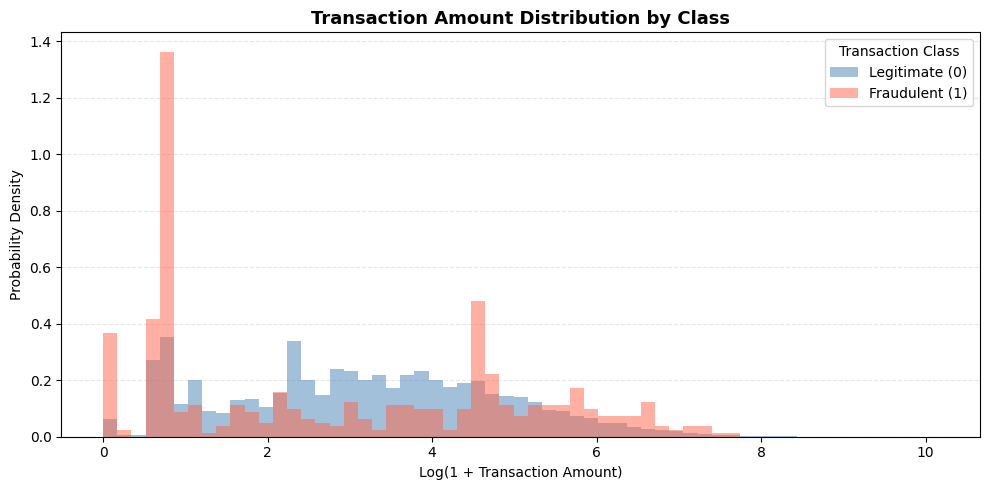

In [8]:

# Extract transaction amounts for each class
legitimate_amounts = creditcard_clean_df.loc[
    creditcard_clean_df["Class"] == 0, "Amount"
]

fraudulent_amounts = creditcard_clean_df.loc[
    creditcard_clean_df["Class"] == 1, "Amount"
]

# Apply log(1 + Amount) for visualization only
legitimate_log = np.log1p(legitimate_amounts)
fraudulent_log = np.log1p(fraudulent_amounts)

# Use common histogram bins for a fair comparison
bins = np.linspace(
    0,
    np.log1p(creditcard_clean_df["Amount"].max()),
    60
)

# Create normalized histograms
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    legitimate_log,
    bins=bins,
    density=True,
    alpha=0.5,
    color="steelblue",
    label="Legitimate (0)"
)

ax.hist(
    fraudulent_log,
    bins=bins,
    density=True,
    alpha=0.5,
    color="tomato",
    label="Fraudulent (1)"
)

# Format the visualization
ax.set_title(
    "Transaction Amount Distribution by Class",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Log(1 + Transaction Amount)")
ax.set_ylabel("Probability Density")
ax.legend(title="Transaction Class")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 5.6.1 Transaction Amount Distribution Findings

The normalized histograms reveal differences in transaction amount patterns between legitimate and fraudulent transactions.

**Key Observations:**

1. **Legitimate Transactions:** Transaction amounts are distributed across a relatively broad range, with several concentrations at different values.

2. **Fraudulent Transactions:** Fraudulent transactions show a strong concentration at smaller amounts and another noticeable peak around a log-transformed amount of 4.8.

3. **Overlapping Distributions:** Both classes overlap across several transaction amount ranges. This suggests that transaction amount alone may not provide sufficient information to distinguish fraudulent transactions reliably.

4. **Class Imbalance:** Normalizing each histogram independently allows the two distributions to be compared despite their substantially different sample sizes.

5. **Preprocessing:** The visualization demonstrates the skewness of transaction amounts. The logarithmic transformation was used only for exploratory visualization, while the original `Amount` values remain unchanged for subsequent preprocessing.

**Conclusion:**

Transaction amount provides useful descriptive information, but additional features are necessary for effective fraud classification. Logistic Regression will use the available numerical features to learn relationships associated with fraudulent transactions.



### 5.7 Correlation Analysis

Correlation analysis is used to investigate the relationships between numerical features and the target variable, `Class`.

Pearson correlation coefficients range from -1 to +1:

- **+1:** Perfect positive linear relationship.
- **-1:** Perfect negative linear relationship.
- **0:** No linear relationship.

Because `Class` is binary (0 or 1), its Pearson correlation with a numerical feature measures the direction and strength of their linear association.

The ten features with the largest absolute correlations with `Class` will be identified and visualized.

This analysis is exploratory only. Correlation does not establish causation or guarantee predictive importance, and features will not be selected based on these full-dataset correlations.


Top 10 Features Correlated with Fraud:


,Correlation with Class
V17,-0.3135
V14,-0.2934
V12,-0.2507
V10,-0.2070
V16,-0.1872
V3,-0.1823
V7,-0.1723
V11,0.1491
V4,0.1293
V18,-0.1053


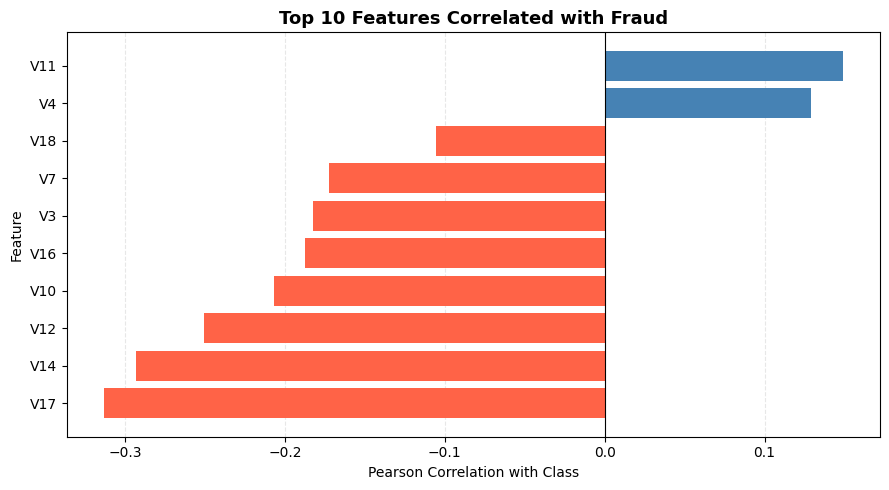

In [9]:

# Calculate Pearson correlations for numerical columns
correlation_matrix = creditcard_clean_df.corr(numeric_only=True)

# Extract correlations with the target variable
target_correlations = (
    correlation_matrix["Class"]
    .drop("Class")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

# Display the ten strongest absolute correlations
print("Top 10 Features Correlated with Fraud:")

display(
    target_correlations.head(10)
    .to_frame(name="Correlation with Class")
    .round(4)
)

# Visualize the top ten correlations
top_correlations = target_correlations.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))

colors = [
    "steelblue" if value >= 0 else "tomato"
    for value in top_correlations.values
]

ax.barh(
    top_correlations.index,
    top_correlations.values,
    color=colors
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Top 10 Features Correlated with Fraud",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Pearson Correlation with Class")
ax.set_ylabel("Feature")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 5.7.1 Correlation Analysis Findings

The Pearson correlation analysis identified several anonymized numerical features associated with fraudulent transactions.

**Key Findings:**

1. **Strongest Negative Correlations:** V17 (-0.3135), V14 (-0.2934), and V12 (-0.2507) have the largest absolute correlations with the target variable. Their negative coefficients indicate that higher feature values tend to be associated with lower fraud occurrence.

2. **Positive Correlations:** V11 (0.1491) and V4 (0.1293) show positive associations with fraudulent transactions.

3. **Correlation Strength:** None of the individual features demonstrates a very strong linear relationship with fraud. However, multiple features may collectively provide useful predictive information.

4. **Feature Interpretation:** Since V1–V28 are anonymized PCA-derived features, their original business meanings are unavailable. Therefore, the observed correlations cannot be interpreted as direct causal relationships.

5. **Modeling Decision:** All 30 numerical predictors will be retained for the initial Logistic Regression model. The full-dataset correlation analysis is used only for descriptive exploration, not for feature selection or model tuning.

**Conclusion:**

The analysis suggests that several anonymized features contain information associated with fraudulent transactions. Logistic Regression will combine these predictors to estimate fraud probabilities.



### 5.8 Train-Test Split (70/30)

The cleaned dataset is divided into training and testing subsets using scikit-learn's `train_test_split()` function.

- **Training set (70%):** Used to train the Logistic Regression model.
- **Testing set (30%):** Reserved for evaluating model performance on unseen observations.
- **Stratified sampling:** Preserves approximately the same proportion of legitimate and fraudulent transactions in both subsets.
- **Random state (42):** Ensures that the split is reproducible.

The target variable `Class` is separated from the predictor features to prevent target leakage.

The test set will remain separate during model fitting and preprocessing.


In [10]:

from sklearn.model_selection import train_test_split

# Separate predictor features and target variable
X = creditcard_clean_df.drop(columns=["Class"])
y = creditcard_clean_df["Class"]

# Split into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

# Compare class distributions in both subsets
split_summary = pd.DataFrame({
    "Training Count": y_train.value_counts().reindex([0, 1]),
    "Testing Count": y_test.value_counts().reindex([0, 1]),
    "Training (%)": (
        y_train.value_counts(normalize=True)
        .reindex([0, 1]) * 100
    ).round(4),
    "Testing (%)": (
        y_test.value_counts(normalize=True)
        .reindex([0, 1]) * 100
    ).round(4)
})

split_summary.index = [
    "Legitimate (0)",
    "Fraudulent (1)"
]

print("\nClass Distribution After Stratified Split:")
display(split_summary)


Training Features: (198608, 30)
Testing Features: (85118, 30)

Training Labels: (198608,)
Testing Labels: (85118,)

Class Distribution After Stratified Split:


,Training Count,Testing Count,Training (%),Testing (%)
Legitimate (0),198277,84976,99.8333,99.8332
Fraudulent (1),331,142,0.1667,0.1668



#### 5.8.1 Train-Test Split Findings

The cleaned dataset was successfully divided into 70% training data and 30% testing data using stratified sampling.

| Transaction Class | Training | Testing |
|---|---:|---:|
| Legitimate (0) | 198,277 | 84,976 |
| Fraudulent (1) | 331 | 142 |
| **Total** | **198,608** | **85,118** |

**Key Findings:**

1. The training dataset contains 198,608 transactions, while the testing dataset contains 85,118 transactions.
2. The fraudulent transaction proportion is approximately 0.167% in both subsets.
3. Stratification successfully preserved the original class imbalance.
4. The training set will be used to fit the model, while the testing set will be reserved for final evaluation.

**Conclusion:**

The stratified 70/30 split provides representative training and testing subsets while maintaining the naturally imbalanced distribution of fraudulent transactions.



### 5.9 Feature Standardization

Logistic Regression is sensitive to differences in feature scales, particularly when regularization is applied.

The dataset contains features with substantially different numerical ranges. For example, `Time` contains values up to 172,792, while the anonymized PCA features have different distributions.

To address these differences, `StandardScaler` is applied to standardize all 30 predictor features.

Standardization uses the following formula:

$$
z = \frac{x - \mu}{\sigma}
$$

Where:
- $x$ represents the original feature value.
- $\mu$ represents the training feature mean.
- $\sigma$ represents the training feature standard deviation.

**Data Leakage Prevention:**

The scaler is fitted exclusively on the training data using `fit_transform()`. The testing data is then standardized using `transform()` without recalculating the scaling parameters.

This ensures that information from the test set does not influence the preprocessing learned from training data.

The target variable `Class` is not standardized.


In [11]:

from sklearn.preprocessing import StandardScaler

# Initialize the feature scaler
scaler = StandardScaler()

# Fit the scaler only on training data
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply training-derived scaling to testing data
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify standardized dataset dimensions
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

# Compare original and standardized feature statistics
features_to_check = ["Time", "Amount", "V17"]

scaling_comparison = pd.DataFrame({
    "Original Mean": X_train[features_to_check].mean(),
    "Original Std": X_train[features_to_check].std(ddof=0),
    "Scaled Mean": X_train_scaled[features_to_check].mean(),
    "Scaled Std": X_train_scaled[features_to_check].std(ddof=0)
})

print("\nFeature Standardization Verification:")
display(scaling_comparison.round(4))

# Check for missing values introduced during scaling
print(
    "\nMissing Values After Scaling:",
    X_train_scaled.isna().sum().sum()
    + X_test_scaled.isna().sum().sum()
)


Scaled Training Shape: (198608, 30)
Scaled Testing Shape: (85118, 30)

Feature Standardization Verification:


,Original Mean,Original Std,Scaled Mean,Scaled Std
Time,94915.8742,47485.4083,-0.0,1.0
Amount,88.3217,242.6128,0.0,1.0
V17,-0.0011,0.8426,-0.0,1.0



Missing Values After Scaling: 0



#### 5.9.1 Feature Standardization Findings

The StandardScaler preprocessing was successfully applied to all 30 predictor features.

**Key Findings:**

1. The training dataset contains 198,608 transactions, and the testing dataset contains 85,118 transactions.
2. The standardized training features have means approximately equal to 0 and standard deviations equal to 1.
3. No missing values were introduced during preprocessing.
4. Scaling parameters were calculated exclusively from the training dataset to prevent data leakage.
5. The original binary target variable, `Class`, remained unchanged.

**Conclusion:**

The numerical features are now standardized and ready for Logistic Regression training.




### 5.10 Logistic Regression Model Training

Logistic Regression is a supervised classification algorithm used to estimate the probability that a transaction belongs to a particular class.

In this lab:
- **Class 0:** Legitimate transaction.
- **Class 1:** Fraudulent transaction.

The model uses the standardized training features to learn relationships between transaction characteristics and fraud occurrence.

**Initial Model Configuration:**

- **Algorithm:** Logistic Regression
- **Solver:** `lbfgs`
- **Maximum iterations:** 1000
- **Class weighting:** None (baseline model)
- **Random state:** 42

The baseline model will be evaluated using the independent test dataset. Because fraudulent transactions are rare, its performance will be assessed using metrics beyond accuracy.

A class-weighted Logistic Regression model may also be compared to investigate how addressing class imbalance affects fraud detection.

In [12]:

from sklearn.linear_model import LogisticRegression

# Initialize the baseline Logistic Regression model
logistic_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

# Train using only the standardized training dataset
logistic_model.fit(X_train_scaled, y_train)

# Verify successful model training
print("Logistic Regression Model Trained Successfully!")

print("\nModel Configuration:")
print("Algorithm: Logistic Regression")
print("Solver:", logistic_model.solver)
print("Maximum Iterations:", logistic_model.max_iter)
print("Actual Iterations:", logistic_model.n_iter_[0])
print("Number of Features:", logistic_model.n_features_in_)
print("Classes:", logistic_model.classes_)


Logistic Regression Model Trained Successfully!

Model Configuration:
Algorithm: Logistic Regression
Solver: lbfgs
Maximum Iterations: 1000
Actual Iterations: 16
Number of Features: 30
Classes: [0 1]



#### 5.10.1 Model Training Findings

The baseline Logistic Regression model was trained successfully using 198,608 standardized training observations and 30 predictor features.

The `lbfgs` solver completed optimization in 16 iterations, below the configured maximum of 1,000 iterations. No convergence warning was reported.

The model recognizes two classes:
- **0:** Legitimate transactions.
- **1:** Fraudulent transactions.


Before evaluating the model on the testing dataset, standard and class-weighted Logistic Regression configurations will be compared using a validation subset drawn exclusively from the training data. This comparison will support model selection without relying on test-set performance.



### 5.11 Model Configuration Comparison (Training-Only Validation)


Because fraudulent transactions are extremely rare, class imbalance may affect the performance of Logistic Regression.

Before presenting the final test evaluation, standard and class-weighted Logistic Regression configurations are compared using a separate validation subset drawn exclusively from the training data.

The objective is to investigate the trade-off between precision and recall and select a model configuration using validation F1-score.


To investigate this limitation, two Logistic Regression configurations will be compared:

1. **Standard Logistic Regression:** Uses the default class weighting.
2. **Balanced Logistic Regression:** Uses `class_weight="balanced"` to assign greater importance to the minority class.

#### Validation Strategy

To avoid selecting model settings based on test-set performance, the original 70% training subset is further divided into:

- **80% development data:** Used to fit the comparison models.
- **20% validation data:** Used to compare their performance.

Stratified sampling preserves the class proportions.

A scikit-learn Pipeline combines StandardScaler and Logistic Regression, ensuring that scaling parameters are learned only from the development data.

Both models use the same validation observations and the default classification threshold of 0.50 for a fair initial comparison.

The original 30% test dataset remains unchanged and will not be used to select the preferred configuration.


In [13]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Create a validation split using training data only
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Development Set:", X_dev.shape)
print("Validation Set:", X_val.shape)

# Define two Logistic Regression configurations
model_configs = {
    "Standard Logistic Regression": None,
    "Balanced Logistic Regression": "balanced"
}

validation_results = []

for model_name, class_weight in model_configs.items():

    # Build a leakage-safe preprocessing and model pipeline
    model_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            solver="lbfgs",
            max_iter=1000,
            class_weight=class_weight,
            random_state=42
        ))
    ])

    # Fit only on development data
    model_pipeline.fit(X_dev, y_dev)

    # Predict using the independent validation subset
    val_predictions = model_pipeline.predict(X_val)
    val_probabilities = model_pipeline.predict_proba(X_val)[:, 1]

    # Extract confusion matrix components
    tn_val, fp_val, fn_val, tp_val = confusion_matrix(
        y_val, val_predictions, labels=[0, 1]
    ).ravel()

    # Collect validation performance
    validation_results.append({
        "Model": model_name,
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, val_predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val, val_probabilities
        ),
        "False Positives": fp_val,
        "False Negatives": fn_val
    })

# Display the model comparison
validation_comparison = pd.DataFrame(validation_results)
validation_comparison = validation_comparison.set_index("Model")

print("\nTraining-Only Validation Comparison:")
display(validation_comparison.round(4))


Development Set: (158886, 30)
Validation Set: (39722, 30)

Training-Only Validation Comparison:


,Precision,Recall,F1-Score,Average Precision,False Positives,False Negatives
Model,,,,,,
Standard Logistic Regression,0.8667,0.5909,0.7027,0.7363,6,27
Balanced Logistic Regression,0.0550,0.8939,0.1036,0.7100,1014,7



#### 5.11.1 Model Configuration Comparison Findings

The two Logistic Regression configurations were evaluated using a stratified validation subset containing 39,722 transactions, drawn exclusively from the original training data.

**Key Findings:**

1. **Standard Logistic Regression:** Achieved 86.67% precision, 59.09% recall, and a 70.27% F1-score. It generated only 6 false positives but missed 27 fraudulent transactions.

2. **Balanced Logistic Regression:** Achieved higher recall (89.39%), reducing missed fraud cases to 7. However, precision decreased to 5.50%, with 1,014 false positives.

3. **Precision-Recall Trade-off:** Class weighting increased the model's sensitivity to fraud but substantially increased the number of legitimate transactions incorrectly flagged as fraudulent.

4. **Average Precision:** The standard model achieved an AP score of 0.7363, compared with 0.7100 for the balanced model. This indicates slightly better precision-recall ranking performance for the standard configuration on this validation subset.

5. **Model Selection:** The standard Logistic Regression configuration is preferred based on its higher validation F1-score and substantially lower false-positive count. F1-score is used as the primary selection criterion for this comparison.

**Limitations:**

The comparison uses a single validation split, and only a small number of fraudulent examples are available. Consequently, the estimated performance may vary with different samples.

The baseline test results were also inspected earlier in the exploratory workflow. Therefore, further model decisions will rely on training-only validation results rather than additional test-set experimentation.

**Conclusion:**

Class weighting improves fraud recall but introduces a considerable false-positive burden at the default threshold of 0.50.

For this lab, the standard Logistic Regression configuration provides a more balanced precision-recall trade-off according to the validation F1-score.

In a real-world fraud detection system, the preferred configuration would also depend on the financial costs of missed fraud and false alarms.


In [14]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Create a validation split using training data only
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Development Set:", X_dev.shape)
print("Validation Set:", X_val.shape)

# Define two Logistic Regression configurations
model_configs = {
    "Standard Logistic Regression": None,
    "Balanced Logistic Regression": "balanced"
}

validation_results = []

for model_name, class_weight in model_configs.items():

    # Build a leakage-safe preprocessing and model pipeline
    model_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            solver="lbfgs",
            max_iter=1000,
            class_weight=class_weight,
            random_state=42
        ))
    ])

    # Fit only on development data
    model_pipeline.fit(X_dev, y_dev)

    # Predict using the independent validation subset
    val_predictions = model_pipeline.predict(X_val)
    val_probabilities = model_pipeline.predict_proba(X_val)[:, 1]

    # Extract confusion matrix components
    tn_val, fp_val, fn_val, tp_val = confusion_matrix(
        y_val, val_predictions, labels=[0, 1]
    ).ravel()

    # Collect validation performance
    validation_results.append({
        "Model": model_name,
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, val_predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val, val_probabilities
        ),
        "False Positives": fp_val,
        "False Negatives": fn_val
    })

# Display the model comparison
validation_comparison = pd.DataFrame(validation_results)
validation_comparison = validation_comparison.set_index("Model")

print("\nTraining-Only Validation Comparison:")
display(validation_comparison.round(4))


Development Set: (158886, 30)
Validation Set: (39722, 30)

Training-Only Validation Comparison:


,Precision,Recall,F1-Score,Average Precision,False Positives,False Negatives
Model,,,,,,
Standard Logistic Regression,0.8667,0.5909,0.7027,0.7363,6,27
Balanced Logistic Regression,0.0550,0.8939,0.1036,0.7100,1014,7


### 5.12 Baseline Logistic Regression Evaluation

The trained Logistic Regression model will be evaluated using the testing dataset, which was not used during model training.

The following evaluation metrics are considered:

1. **Accuracy:** Proportion of all correctly classified transactions.
2. **Precision:** Proportion of predicted fraudulent transactions that are actually fraudulent.
3. **Recall:** Proportion of actual fraudulent transactions correctly detected.
4. **F1-Score:** Harmonic mean of precision and recall.
5. **Confusion Matrix:** Counts of true negatives, false positives, false negatives, and true positives.
6. **ROC-AUC:** Measures how well the model ranks fraudulent transactions above legitimate transactions across classification thresholds.
7. **Average Precision (AP):** Summarizes precision-recall performance across thresholds, which is especially useful for imbalanced classification.

A default probability threshold of 0.50 is used for the baseline classification predictions.

Because only approximately 0.167% of test transactions are fraudulent, accuracy alone is insufficient for evaluating fraud detection performance. A majority-class baseline will also be calculated for comparison.


In [15]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Predict transaction classes using the trained model
y_pred = logistic_model.predict(X_test_scaled)

# Obtain probabilities for the fraudulent class (Class 1)
y_pred_proba = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Calculate classification performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Calculate probability-based evaluation metrics
roc_auc = roc_auc_score(y_test, y_pred_proba)
average_precision = average_precision_score(y_test, y_pred_proba)

# Calculate majority-class baseline accuracy
majority_baseline_accuracy = (y_test == 0).mean()

# Display model performance
print("Baseline Logistic Regression Performance")
print("-" * 45)

print(f"Accuracy:          {accuracy:.6f}")
print(f"Precision:         {precision:.6f}")
print(f"Recall:            {recall:.6f}")
print(f"F1-Score:          {f1:.6f}")
print(f"ROC-AUC:           {roc_auc:.6f}")
print(f"Average Precision: {average_precision:.6f}")

print(
    f"\nMajority-Class Baseline Accuracy: "
    f"{majority_baseline_accuracy:.6f}"
)

# Display detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate (0)", "Fraudulent (1)"],
        zero_division=0
    )
)

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Extract confusion matrix components
tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix Breakdown:")
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")


Baseline Logistic Regression Performance
---------------------------------------------
Accuracy:          0.999084
Precision:         0.840426
Recall:            0.556338
F1-Score:          0.669492
ROC-AUC:           0.964678
Average Precision: 0.704037

Majority-Class Baseline Accuracy: 0.998332

Classification Report:
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00     84976
Fraudulent (1)       0.84      0.56      0.67       142

      accuracy                           1.00     85118
     macro avg       0.92      0.78      0.83     85118
  weighted avg       1.00      1.00      1.00     85118

Confusion Matrix:
[[84961    15]
 [   63    79]]

Confusion Matrix Breakdown:
True Negatives  (TN): 84961
False Positives (FP): 15
False Negatives (FN): 63
True Positives  (TP): 79



#### 5.12.1 Baseline Logistic Regression Evaluation Findings

The baseline Logistic Regression model was evaluated on 85,118 unseen test transactions.

**Performance Results:**

| Evaluation Metric | Result |
|---|---:|
| Accuracy | 99.91% |
| Precision (Fraud) | 84.04% |
| Recall (Fraud) | 55.63% |
| F1-Score (Fraud) | 66.95% |
| ROC-AUC | 0.9647 |
| Average Precision | 0.7040 |
| Majority-Class Baseline Accuracy | 99.83% |

**Key Findings:**

1. **Accuracy:** The model correctly classified approximately 99.91% of all test transactions. This exceeds the majority-class baseline accuracy of 99.83%.

2. **Precision:** Of all transactions predicted as fraudulent, approximately 84.04% were actually fraudulent. Therefore, most fraud alerts generated by the model were correct.

3. **Recall:** The model identified only 55.63% of actual fraudulent transactions, meaning approximately 44.37% of fraudulent transactions were missed.

4. **F1-Score:** The fraud-class F1-score of 66.95% reflects the balance between precision and recall at the default classification threshold.

5. **ROC-AUC:** The ROC-AUC of 0.9647 indicates strong discrimination between legitimate and fraudulent transactions across classification thresholds.

6. **Average Precision:** The average precision of 0.7040 indicates useful precision-recall performance in this highly imbalanced classification problem.

**Confusion Matrix Interpretation:**

- **True Negatives (TN):** 84,961 legitimate transactions correctly classified.
- **False Positives (FP):** 15 legitimate transactions incorrectly flagged as fraudulent.
- **False Negatives (FN):** 63 fraudulent transactions incorrectly classified as legitimate.
- **True Positives (TP):** 79 fraudulent transactions correctly detected.

**Conclusion:**

Although the baseline model achieves excellent overall accuracy and relatively high fraud precision, its recall remains limited.

The model successfully detected 79 of 142 fraudulent transactions but missed 63. These false negatives are important because undetected fraud may lead to financial losses.

Therefore, additional analysis of class imbalance and the precision-recall trade-off is necessary before considering this model suitable for practical fraud detection.



### 5.13 Confusion Matrix Visualization

A confusion matrix provides a detailed breakdown of the Logistic Regression model's predictions.

The matrix compares actual transaction classes with predicted transaction classes, identifying:

- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)
- True Positives (TP)

Because the test dataset is highly imbalanced, the heatmap is normalized by actual class to make the minority-class performance visible.

Each cell displays both the original transaction count and its percentage within the corresponding actual class.


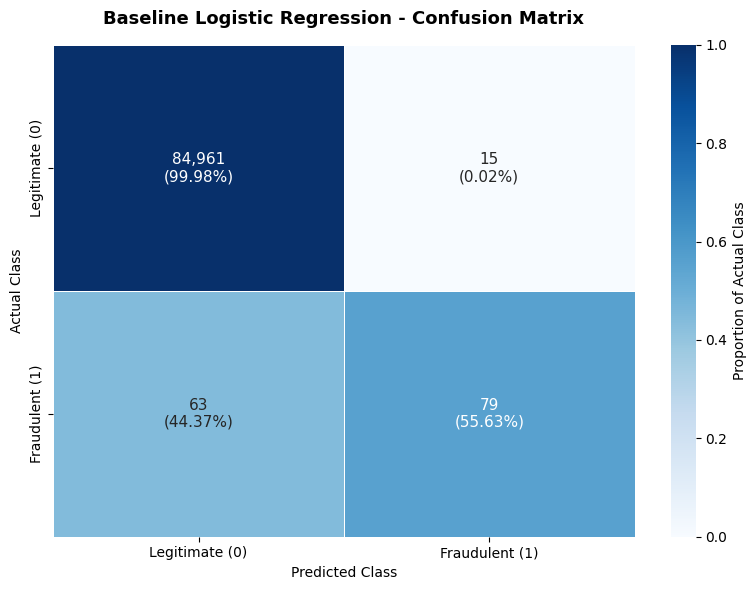

In [16]:

# Normalize the confusion matrix by actual class
cm_normalized = cm / cm.sum(axis=1, keepdims=True)

# Create annotations containing counts and percentages
cm_annotations = np.array([
    [
        f"{cm[i, j]:,}\n({cm_normalized[i, j]:.2%})"
        for j in range(cm.shape[1])
    ]
    for i in range(cm.shape[0])
])

# Create the normalized confusion matrix heatmap
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm_normalized,
    annot=cm_annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    xticklabels=["Legitimate (0)", "Fraudulent (1)"],
    yticklabels=["Legitimate (0)", "Fraudulent (1)"],
    cbar_kws={"label": "Proportion of Actual Class"},
    annot_kws={"fontsize": 11},
    ax=ax
)

# Add descriptive title and axis labels
ax.set_title(
    "Baseline Logistic Regression - Confusion Matrix",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()



#### 5.13.1 Confusion Matrix Findings

The normalized confusion matrix provides a detailed evaluation of the baseline Logistic Regression model on 85,118 test transactions.

**Key Findings:**

1. **True Negatives (84,961):** The model correctly identified 99.98% of legitimate transactions.

2. **False Positives (15):** Only 0.02% of legitimate transactions were incorrectly flagged as fraudulent, indicating a low false-positive rate.

3. **False Negatives (63):** The model incorrectly classified 44.37% of actual fraudulent transactions as legitimate.

4. **True Positives (79):** The model successfully detected 55.63% of fraudulent transactions.

**Interpretation:**

The model performs exceptionally well at identifying legitimate transactions while generating relatively few false fraud alerts.

However, its fraud detection recall is considerably lower. Of the 142 actual fraudulent transactions in the test dataset, 63 were missed.

This result demonstrates why the model's 99.91% overall accuracy does not fully represent its effectiveness in fraud detection.

**Conclusion:**

The baseline Logistic Regression model achieves high precision but moderate fraud recall at the default classification threshold of 0.50.

A practical fraud detection system must carefully balance the consequences of missed fraudulent transactions against incorrectly flagged legitimate transactions.

Further analysis will investigate the precision-recall relationship and explore whether class-weighted Logistic Regression can improve fraud detection without introducing excessive false positives.



### 5.14 Precision-Recall Curve Analysis

The Precision-Recall (PR) curve evaluates the relationship between precision and recall across different classification thresholds.

- **Precision:** Measures how many predicted fraudulent transactions are actually fraudulent.
- **Recall:** Measures how many actual fraudulent transactions are successfully detected.

Lowering the classification threshold may identify additional fraudulent transactions, but it can also increase false-positive predictions.

The Average Precision (AP) score summarizes the model's precision-recall performance across thresholds.

The proportion of fraudulent transactions in the testing dataset is used as a reference baseline.

This analysis is intended to explain the model's classification performance, not to select a threshold using the test dataset.


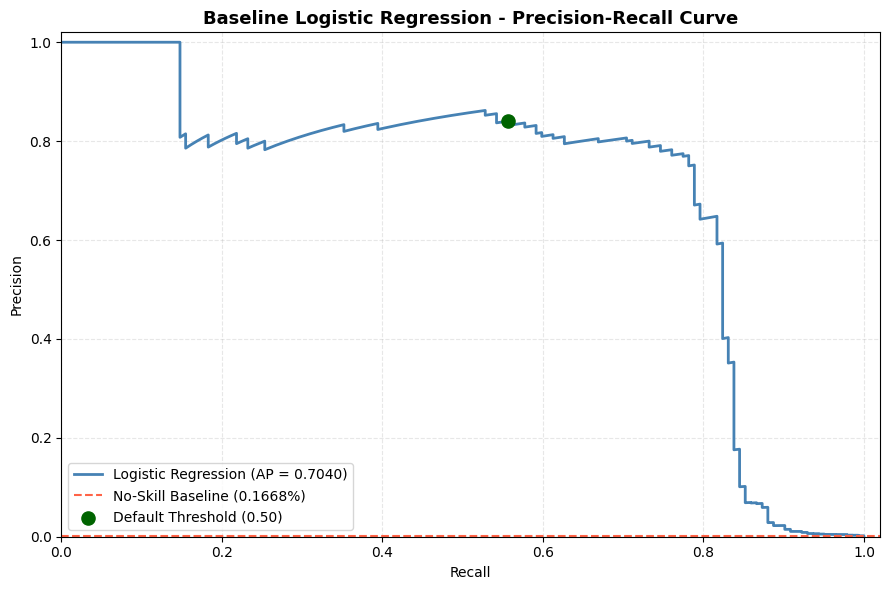

Average Precision: 0.7040
Fraud Prevalence: 0.1668%
Precision at Threshold 0.50: 84.0426%
Recall at Threshold 0.50: 55.6338%


In [17]:

from sklearn.metrics import precision_recall_curve

# Calculate precision and recall at different thresholds
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_pred_proba
)

# Calculate the positive-class prevalence
fraud_prevalence = y_test.mean()

# Create the Precision-Recall curve
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    pr_recall,
    pr_precision,
    color="steelblue",
    linewidth=2,
    label=f"Logistic Regression (AP = {average_precision:.4f})"
)

# Add the no-skill reference baseline
ax.axhline(
    y=fraud_prevalence,
    color="tomato",
    linestyle="--",
    linewidth=1.5,
    label=f"No-Skill Baseline ({fraud_prevalence:.4%})"
)

# Highlight the default 0.50 threshold performance
ax.scatter(
    recall,
    precision,
    color="darkgreen",
    s=90,
    zorder=5,
    label="Default Threshold (0.50)"
)

# Format the visualization
ax.set_title(
    "Baseline Logistic Regression - Precision-Recall Curve",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower left")
ax.grid(linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Display summary results
print(f"Average Precision: {average_precision:.4f}")
print(f"Fraud Prevalence: {fraud_prevalence:.4%}")
print(f"Precision at Threshold 0.50: {precision:.4%}")
print(f"Recall at Threshold 0.50: {recall:.4%}")



#### 5.14.1 Precision-Recall Curve Findings

The Precision-Recall curve evaluates how the baseline Logistic Regression model performs at different classification thresholds.

**Key Findings:**

1. **Average Precision:** The model achieved an Average Precision (AP) score of 0.7040, indicating useful precision-recall performance across different classification thresholds.

2. **Class Imbalance:** The no-skill baseline is approximately 0.1668%, reflecting the extremely low proportion of fraudulent transactions in the test dataset. The model performs substantially better than this reference.

3. **Default Threshold (0.50):** At the default classification threshold, the model achieved 84.04% precision and 55.63% recall.

4. **Precision-Recall Trade-off:** The curve shows that precision generally decreases when attempting to detect a greater proportion of fraudulent transactions. This decline becomes particularly noticeable at higher recall levels.

5. **Model Limitations:** Although the model demonstrates strong overall accuracy and useful fraud detection capabilities, it still misses approximately 44.37% of actual fraudulent transactions at the default threshold.

**Conclusion:**

The Precision-Recall curve confirms that the baseline Logistic Regression model performs substantially better than random ranking but does not detect every fraudulent transaction.

Improving fraud recall may require accepting additional false-positive predictions.


The earlier training-only validation comparison selected standard Logistic Regression based on its higher F1-score.

The final test evaluation demonstrates the selected model's strengths and limitations, particularly its high precision and moderate fraud recall.

Future improvements could investigate decision-threshold optimization, cross-validation, and alternative imbalance-handling strategies using training-only data.



### 5.15 Part A — Final Conclusion

This part of the lab successfully developed and evaluated a Logistic Regression model for credit card fraud detection.

**Data Preparation and Analysis:**

- The original dataset contained 284,807 transactions.
- After removing 1,081 exact duplicate records, 283,726 transactions remained.
- No missing values were identified.
- Only 473 transactions (approximately 0.167%) were fraudulent, demonstrating severe class imbalance.
- A stratified 70/30 train-test split was applied.
- StandardScaler was fitted exclusively on training data to prevent preprocessing leakage.

**Baseline Model Performance:**

| Metric | Test Result |
|---|---:|
| Accuracy | 99.91% |
| Fraud Precision | 84.04% |
| Fraud Recall | 55.63% |
| Fraud F1-Score | 66.95% |
| ROC-AUC | 0.9647 |
| Average Precision | 0.7040 |

The baseline model correctly detected 79 of 142 fraudulent test transactions, while 63 fraudulent transactions were missed. Only 15 legitimate transactions were incorrectly flagged as fraudulent.

**Class-Weighting Comparison:**

A separate validation subset was used to compare standard and balanced Logistic Regression configurations.

The balanced model improved validation fraud recall from 59.09% to 89.39%. However, false positives increased from 6 to 1,014, and precision decreased considerably.

The standard Logistic Regression configuration was selected based on its higher validation F1-score (0.7027 versus 0.1036). The final test results reported above correspond to this configuration trained on the full original training subset.

**Limitations:**

- Severe class imbalance makes overall accuracy misleading.
- The baseline model misses a substantial proportion of fraudulent transactions.
- Exact duplicate removal may also remove distinct transactions with identical recorded features.
- The validation comparison relies on a single stratified split.
- Test performance was inspected earlier in the notebook; model selection subsequently relied on training-only validation results, but a completely untouched final test evaluation would provide stronger methodological assurance.

**Overall Conclusion:**

Logistic Regression provides a useful baseline for credit card fraud detection, achieving high precision and strong ROC-AUC performance.

However, the model's moderate fraud recall indicates that further development would be necessary before practical deployment.

The results highlight the importance of appropriate preprocessing, stratified sampling, multiple evaluation metrics, and careful consideration of the precision-recall trade-off when working with imbalanced datasets.



---

## 6. Part B — Insurance Cost Prediction Using Linear Regression

### 6.1 Problem Statement and Dataset Overview

The objective of Part B is to develop a supervised machine learning regression model that predicts individual medical insurance costs using Linear Regression.

The dataset contains demographic, health-related, and lifestyle characteristics that may influence insurance charges.

**Dataset:** Medical Cost Personal Dataset  
**Source:** Kaggle — Mirichoi  
**File:** `insurance.csv`  
**Target Variable:** `charges`  
**Algorithm:** Linear Regression  
**Train-Test Split:** 70% training and 30% testing

#### Dataset Features

| Feature | Description |
|---|---|
| `age` | Age of the insured individual |
| `sex` | Biological sex recorded in the dataset |
| `bmi` | Body Mass Index |
| `children` | Number of children covered by insurance |
| `smoker` | Smoking status (yes/no) |
| `region` | Residential region |
| `charges` | Individual medical insurance charges (target) |

#### Planned Workflow

1. Load and inspect the dataset.
2. Examine data types, missing values, and duplicates.
3. Perform exploratory data analysis and visualization.
4. Encode categorical variables and prepare numerical features.
5. Split the dataset into 70% training and 30% testing.
6. Train a Linear Regression model.
7. Evaluate predictions using MAE, MSE, RMSE, and R².
8. Interpret results, residuals, and model limitations.

The regression model will predict continuous insurance charges rather than classify individuals into categories.


In [18]:

# Load the medical insurance dataset
insurance_df = pd.read_csv("insurance.csv")

# Display dataset dimensions
print("Insurance Dataset Shape:", insurance_df.shape)

# Display column names
print("\nColumn Names:")
print(insurance_df.columns.tolist())

# Display the first five records
print("\nFirst Five Records:")
display(insurance_df.head())


Insurance Dataset Shape: (1338, 7)

Column Names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

First Five Records:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



### 6.2 Data Quality Assessment

Before developing the Linear Regression model, the insurance dataset is examined for potential data quality issues.

The following checks are performed:

1. **Data Types:** Identify numerical and categorical features requiring different preprocessing techniques.
2. **Missing Values:** Determine whether any observations require imputation.
3. **Duplicate Records:** Identify repeated records that may influence model training and evaluation.
4. **Categorical Values:** Examine the unique categories in `sex`, `smoker`, and `region` to plan appropriate encoding.

These checks help ensure that the dataset is suitable for regression analysis and that preprocessing decisions are based on the observed data.

Duplicate records will be investigated before deciding whether removal is appropriate.


In [19]:

# Examine dataset information and data types
print("Insurance Dataset Information:")
insurance_df.info()

# Check missing values in each column
print("\nMissing Values by Column:")
missing_values_insurance = insurance_df.isnull().sum()

display(
    missing_values_insurance.to_frame(name="Missing Values")
)

print(
    "Total Missing Values:",
    missing_values_insurance.sum()
)

# Check for exact duplicate records
duplicate_count_insurance = insurance_df.duplicated().sum()

print("\nTotal Duplicate Records:", duplicate_count_insurance)

# Identify numerical and categorical columns
numerical_columns = insurance_df.select_dtypes(
    include=["number"]
).columns.tolist()


categorical_columns = insurance_df.select_dtypes(
    include=["str", "category"]
).columns.tolist()


print("\nNumerical Columns:", numerical_columns)
print("Categorical Columns:", categorical_columns)

# Examine unique categorical values
print("\nUnique Categorical Values:")

for column in categorical_columns:
    print(f"{column}: {insurance_df[column].unique().tolist()}")


Insurance Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Missing Values by Column:


,Missing Values
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


Total Missing Values: 0

Total Duplicate Records: 1

Numerical Columns: ['age', 'bmi', 'children', 'charges']
Categorical Columns: ['sex', 'smoker', 'region']

Unique Categorical Values:
sex: ['female', 'male']
smoker: ['yes', 'no']
region: ['southwest', 'southeast', 'northwest', 'northeast']



#### 6.2.1 Data Quality Assessment Findings

The insurance dataset contains 1,338 observations and 7 columns.

**Key Findings:**

1. **Data Types:** The dataset contains three numerical predictor features (`age`, `bmi`, and `children`), three categorical predictor features (`sex`, `smoker`, and `region`), and one continuous numerical target variable (`charges`).

2. **Missing Values:** No missing values were identified in any column. Therefore, missing-value imputation is unnecessary.

3. **Duplicate Records:** One exact duplicate record was identified. Further inspection is required before deciding whether it should be removed.

4. **Categorical Features:**
   - `sex`: female, male
   - `smoker`: yes, no
   - `region`: southwest, southeast, northwest, northeast

5. **Preprocessing Requirements:** Categorical predictors must be converted into numerical representations before training Linear Regression. One-hot encoding will be considered to avoid introducing an artificial ordering among categories.

**Conclusion:**

The dataset is largely complete and suitable for further analysis. However, the duplicate observation requires investigation, and categorical features must be encoded before model training.

The original dataset will be preserved so that preprocessing steps remain transparent and reproducible.


In [20]:

# Identify all occurrences of duplicated insurance records
duplicate_rows = insurance_df[
    insurance_df.duplicated(keep=False)
].copy()

print("Duplicate Records Including Original Occurrences:")
display(duplicate_rows)

print("\nNumber of Rows in Duplicate Groups:", len(duplicate_rows))

print(
    "Number of Duplicate Rows Beyond First Occurrence:",
    insurance_df.duplicated().sum()
)


Duplicate Records Including Original Occurrences:


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631



Number of Rows in Duplicate Groups: 2
Number of Duplicate Rows Beyond First Occurrence: 1



#### 6.2.2 Duplicate Record Investigation and Cleaning

The duplicate investigation identified two identical observations at original row indexes 195 and 581.

Both records describe a 19-year-old male, with a BMI of 30.59, no children, non-smoking status, northwest region, and insurance charges of 1,639.5631.

Since the dataset does not contain unique customer identifiers, it is not possible to determine whether these observations represent the same individual.

**Preprocessing Decision:**

For this analysis, the additional duplicate record will be removed before splitting the dataset. This reduces the possibility of identical recorded observations appearing in both the training and testing sets.

The first occurrence will be retained, and the original DataFrame will remain unchanged.

This decision is a data-cleaning assumption rather than proof that the repeated observation is erroneous.


In [21]:

# Remove exact duplicate records while preserving the original dataset
insurance_clean_df = insurance_df.drop_duplicates().copy()

# Reset the index after cleaning
insurance_clean_df.reset_index(drop=True, inplace=True)

# Compare original and cleaned datasets
print("Original Dataset Shape:", insurance_df.shape)
print("Cleaned Dataset Shape:", insurance_clean_df.shape)

print(
    "\nRecords Removed:",
    len(insurance_df) - len(insurance_clean_df)
)

# Verify that no duplicate records remain
print(
    "Remaining Duplicates:",
    insurance_clean_df.duplicated().sum()
)

# Confirm that no missing values were introduced
print(
    "Total Missing Values:",
    insurance_clean_df.isnull().sum().sum()
)


Original Dataset Shape: (1338, 7)
Cleaned Dataset Shape: (1337, 7)

Records Removed: 1
Remaining Duplicates: 0
Total Missing Values: 0



### 6.3 Descriptive Statistical Analysis

Descriptive statistics are used to understand the distribution, central tendency, and variability of numerical features in the cleaned insurance dataset.

The analysis focuses on the following variables:

- **Age:** Age of the insured individual.
- **BMI:** Body Mass Index.
- **Children:** Number of children covered by insurance.
- **Charges:** Individual medical insurance charges (target variable).

The following statistics will be examined:

1. **Count:** Number of observations.
2. **Mean:** Average value.
3. **Median (50%):** Middle value of the distribution.
4. **Standard Deviation:** Variability of observations.
5. **Minimum and Maximum:** Range of observed values.
6. **Quartiles (25% and 75%):** Distribution of values.
7. **Skewness:** Degree of asymmetry in the distribution.

Understanding the distribution of insurance charges is particularly important because Linear Regression predictions may be influenced by extreme values and non-linear relationships.


In [22]:

# Select numerical variables for descriptive analysis
insurance_numeric = insurance_clean_df[
    ["age", "bmi", "children", "charges"]
]

# Calculate descriptive statistics
print("Descriptive Statistics of Insurance Dataset:")

display(
    insurance_numeric.describe().T.round(2)
)

# Calculate skewness of numerical variables
print("\nSkewness of Numerical Variables:")

display(
    insurance_numeric.skew()
    .round(4)
    .to_frame(name="Skewness")
)

# Calculate additional statistics for insurance charges
print("\nInsurance Charges Summary:")

print(
    f"Mean Charges: {insurance_clean_df['charges'].mean():,.2f}"
)

print(
    f"Median Charges: {insurance_clean_df['charges'].median():,.2f}"
)

print(
    f"Minimum Charges: {insurance_clean_df['charges'].min():,.2f}"
)

print(
    f"Maximum Charges: {insurance_clean_df['charges'].max():,.2f}"
)


Descriptive Statistics of Insurance Dataset:


,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.22,14.04,18.00,27.00,39.00,51.00,64.00
bmi,1337.0,30.66,6.10,15.96,26.29,30.40,34.70,53.13
children,1337.0,1.10,1.21,0.00,0.00,1.00,2.00,5.00
charges,1337.0,13279.12,12110.36,1121.87,4746.34,9386.16,16657.72,63770.43



Skewness of Numerical Variables:


,Skewness
age,0.0548
bmi,0.2839
children,0.9374
charges,1.5154



Insurance Charges Summary:
Mean Charges: 13,279.12
Median Charges: 9,386.16
Minimum Charges: 1,121.87
Maximum Charges: 63,770.43



#### 6.3.1 Descriptive Statistics Findings

The descriptive analysis of the cleaned insurance dataset containing 1,337 observations revealed the following findings.

**1. Age Distribution**
- The average age is 39.22 years, with a median of 39 years.
- Ages range from 18 to 64 years.
- Skewness is approximately 0.0548, indicating a nearly symmetric distribution.

**2. Body Mass Index (BMI)**
- The average BMI is 30.66, with a median of 30.40.
- BMI values range from 15.96 to 53.13.
- Skewness is 0.2839, indicating a slightly right-skewed distribution.

**3. Number of Children**
- The average number of children is approximately 1.10.
- Values range from 0 to 5.
- Skewness is 0.9374, indicating a right-skewed distribution.

**4. Insurance Charges**
- Mean charges: 13,279.12
- Median charges: 9,386.16
- Standard deviation: 12,110.36
- Minimum charges: 1,121.87
- Maximum charges: 63,770.43
- Skewness: 1.5154

The mean insurance charge is substantially higher than the median, indicating that the distribution is positively skewed. A smaller number of individuals with relatively high charges increases the overall average.

**5. Implications for Linear Regression**

The large variation and right-skewness of insurance charges suggest that the regression model may experience larger prediction errors for some high-cost observations.

However, a skewed target variable does not automatically violate Linear Regression assumptions. Model adequacy will be assessed using prediction errors, R², and residual diagnostics.

**Conclusion:**

The dataset contains considerable variation in medical insurance charges. Additional exploratory analysis will investigate the target distribution and its relationships with demographic and lifestyle features before developing the Linear Regression model.



### 6.4 Distribution of Insurance Charges

A histogram with a Kernel Density Estimate (KDE) is used to visualize the distribution of medical insurance charges.

The visualization includes vertical reference lines representing the mean and median insurance charges.

This analysis helps identify:

1. Concentrations of low, moderate, and high insurance charges.
2. The shape and skewness of the target distribution.
3. Differences between the mean and median.
4. The presence of a long upper tail containing relatively expensive insurance observations.

The original charges are used without transformation so that the distribution can be interpreted in its original measurement units.


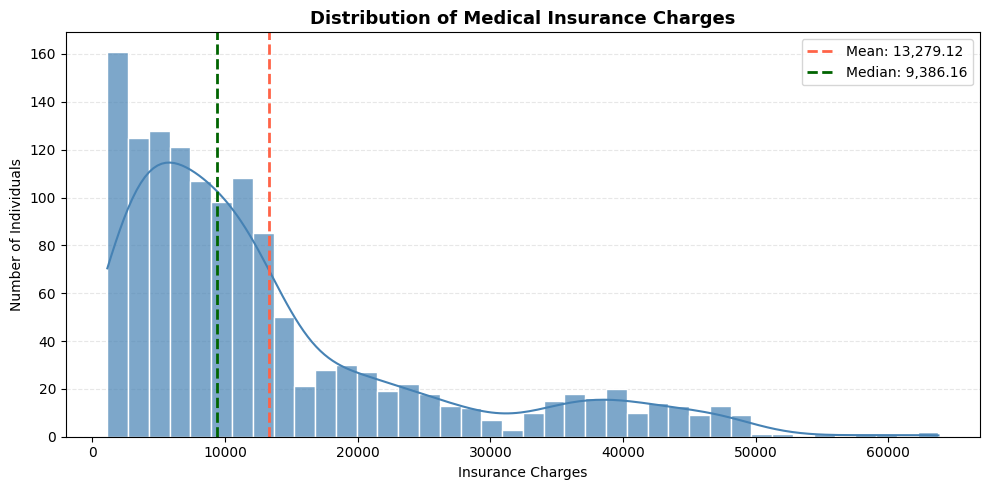

In [23]:

# Calculate the mean and median insurance charges
mean_charges = insurance_clean_df["charges"].mean()
median_charges = insurance_clean_df["charges"].median()

# Create the insurance charges distribution plot
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=insurance_clean_df,
    x="charges",
    bins=40,
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.7,
    ax=ax
)

# Add mean and median reference lines
ax.axvline(
    mean_charges,
    color="tomato",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_charges:,.2f}"
)

ax.axvline(
    median_charges,
    color="darkgreen",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_charges:,.2f}"
)

# Format the visualization
ax.set_title(
    "Distribution of Medical Insurance Charges",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Insurance Charges")
ax.set_ylabel("Number of Individuals")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 6.4.1 Insurance Charges Distribution Findings

The histogram and Kernel Density Estimate (KDE) reveal a positively skewed distribution of medical insurance charges.

**Key Findings:**

1. **Lower-Cost Concentration:** Most observations are concentrated at relatively lower insurance charges, particularly below 15,000.

2. **Positive Skewness:** The mean insurance charge (13,279.12) exceeds the median (9,386.16), consistent with the calculated skewness of 1.5154.

3. **High-Cost Observations:** A smaller number of individuals have substantially higher charges, with the maximum reaching 63,770.43.

4. **Distribution Pattern:** The visualization shows a long right tail and a smaller concentration of observations around 35,000–45,000.

5. **Regression Implications:** The variation in charges suggests that some observations may be more difficult to predict accurately using a simple linear model.

**Conclusion:**

Insurance charges are not symmetrically distributed. High-cost observations influence the overall average and may contribute to larger prediction errors.

Further analysis will investigate how insurance charges vary across smoking status, age, and BMI. These relationships may help explain some of the variation in the target variable.



### 6.5 Insurance Charges by Smoking Status

Smoking status is a categorical predictor that may be associated with differences in medical insurance charges.

This analysis compares insurance costs between smokers and non-smokers using the following statistics:

- Number of individuals in each group.
- Mean insurance charges.
- Median insurance charges.
- Standard deviation of charges.
- Minimum and maximum charges.

The purpose is to identify whether smoking status is associated with higher insurance costs and whether the two groups exhibit different levels of variation.

These findings represent associations within the dataset and do not establish causation.


In [24]:

# Compare insurance charges by smoking status
smoking_summary = (
    insurance_clean_df
    .groupby("smoker")["charges"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std",
        Minimum="min",
        Maximum="max"
    )
    .reindex(["no", "yes"])
    .round(2)
)

# Rename index labels for readability
smoking_summary.index = ["Non-Smoker", "Smoker"]

print("Insurance Charges by Smoking Status:")
display(smoking_summary)

# Calculate the ratio of mean charges
mean_ratio = (
    smoking_summary.loc["Smoker", "Mean"]
    / smoking_summary.loc["Non-Smoker", "Mean"]
)

print(
    f"\nMean Charges Ratio (Smoker / Non-Smoker): "
    f"{mean_ratio:.2f}"
)


Insurance Charges by Smoking Status:


,Count,Mean,Median,Std_Dev,Minimum,Maximum
Non-Smoker,1063,8440.66,7345.73,5992.97,1121.87,36910.61
Smoker,274,32050.23,34456.35,11541.55,12829.46,63770.43



Mean Charges Ratio (Smoker / Non-Smoker): 3.80



#### 6.5.1 Insurance Charges by Smoking Status — Findings

The analysis reveals a substantial difference in insurance charges between smokers and non-smokers.

**Key Findings:**

1. **Group Distribution:** The cleaned dataset contains 1,063 non-smokers and 274 smokers.

2. **Mean Insurance Charges:** Smokers have average charges of 32,050.23, compared with 8,440.66 for non-smokers. Therefore, smokers have approximately 3.80 times higher average insurance charges.

3. **Median Insurance Charges:** The median charge for smokers is 34,456.35, compared with 7,345.73 for non-smokers. This indicates a substantial difference in typical insurance costs between the two groups.

4. **Variability:** The standard deviation is higher among smokers (11,541.55) than non-smokers (5,992.97), indicating greater absolute variation in smokers' insurance charges.

5. **Maximum Charges:** The highest recorded charge is 63,770.43 for smokers, compared with 36,910.61 for non-smokers.

**Interpretation:**

Smoking status is strongly associated with medical insurance charges in this dataset and is likely to be an informative predictor for Linear Regression.

However, these descriptive differences do not establish a causal relationship because other characteristics may also influence insurance costs.

**Conclusion:**

Smoking status should be retained as a predictor and appropriately encoded before model training. A boxplot will be used to visualize differences in the central tendency, spread, and extreme values of insurance charges between both groups.



### 6.6 Boxplot of Insurance Charges by Smoking Status

A boxplot is used to compare the distributions of insurance charges between smokers and non-smokers.

The visualization highlights:

- **Median:** The middle insurance charge within each group.
- **Interquartile Range (IQR):** The spread between the 25th and 75th percentiles.
- **Whiskers:** The range of values within 1.5 times the IQR from the quartiles.
- **Outliers:** Observations beyond the whiskers.

This visualization provides additional insight into the differences in insurance charges between smoking groups.

Statistical outliers are retained because unusually high insurance costs may represent valid observations.


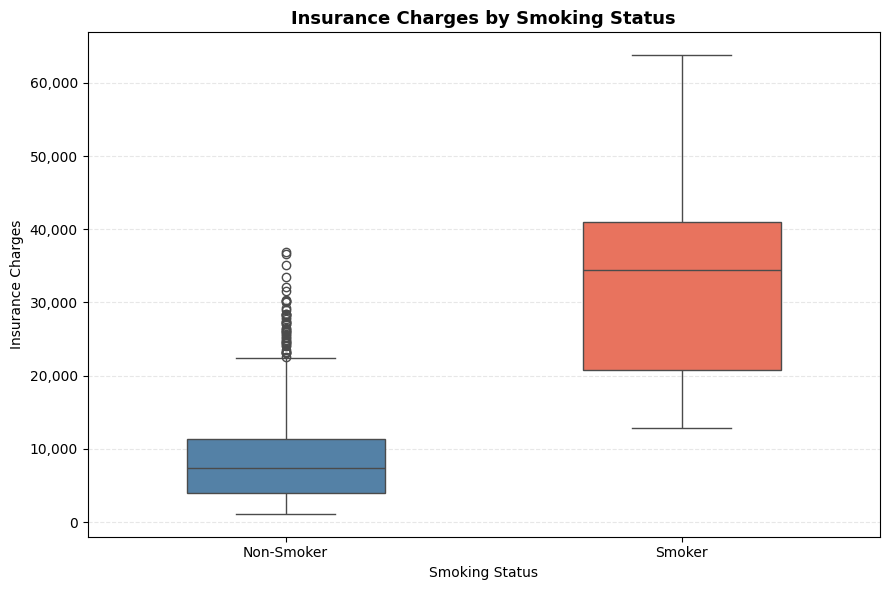

In [25]:

from matplotlib.ticker import StrMethodFormatter

# Create a boxplot comparing charges by smoking status
fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=insurance_clean_df,
    x="smoker",
    y="charges",
    order=["no", "yes"],
    hue="smoker",
    palette={"no": "steelblue", "yes": "tomato"},
    dodge=False,
    legend=False,
    width=0.5,
    showfliers=True,
    ax=ax
)

# Format category labels
ax.set_xticks([0, 1])
ax.set_xticklabels(["Non-Smoker", "Smoker"])

# Add descriptive title and axis labels
ax.set_title(
    "Insurance Charges by Smoking Status",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Smoking Status")
ax.set_ylabel("Insurance Charges")

# Format large values with thousands separators
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Improve readability
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 6.6.1 Boxplot Findings

The boxplot highlights substantial differences in insurance charge distributions between smokers and non-smokers.

**Key Findings:**

1. **Median Charges:** Smokers have considerably higher median insurance charges (34,456.35) than non-smokers (7,345.73).

2. **Interquartile Range:** The smoker group has a wider interquartile range, indicating greater variation in insurance charges among the middle 50% of observations.

3. **Non-Smoker Outliers:** Several non-smokers have unusually high charges, reaching approximately 36,910.61. These observations appear beyond the upper boxplot whisker but are not necessarily invalid records.

4. **Smoker Distribution:** Insurance charges among smokers extend to approximately 63,770.43, with a broader overall distribution than the non-smoker group.

5. **Group Differences:** Although some insurance charge values overlap between the groups, the central tendency of the smoker group is substantially higher.

**Interpretation:**

The visualization supports the descriptive statistical finding that smoking status is strongly associated with insurance charges.

However, smoking status alone may not fully explain insurance costs because other variables, including age, BMI, and individual characteristics, may also contribute.

**Conclusion:**

Smoking status appears to be an informative predictor for insurance cost estimation. It will be retained and appropriately encoded for the Linear Regression model.

The high-cost observations will also be retained because there is insufficient evidence to classify them as data errors.



### 6.7 Relationship Between Age and Insurance Charges

A scatterplot is used to examine the relationship between age and medical insurance charges.

Each point represents one individual, with different colors indicating smoking status.

This visualization helps investigate:

1. Whether insurance charges generally increase with age.
2. Whether smokers and non-smokers exhibit different cost patterns.
3. Whether there is substantial variation in charges among individuals of similar ages.
4. Whether the relationship appears approximately linear or contains patterns that may not be fully captured by simple Linear Regression.

The purpose of this analysis is to identify observable associations rather than establish causal relationships.


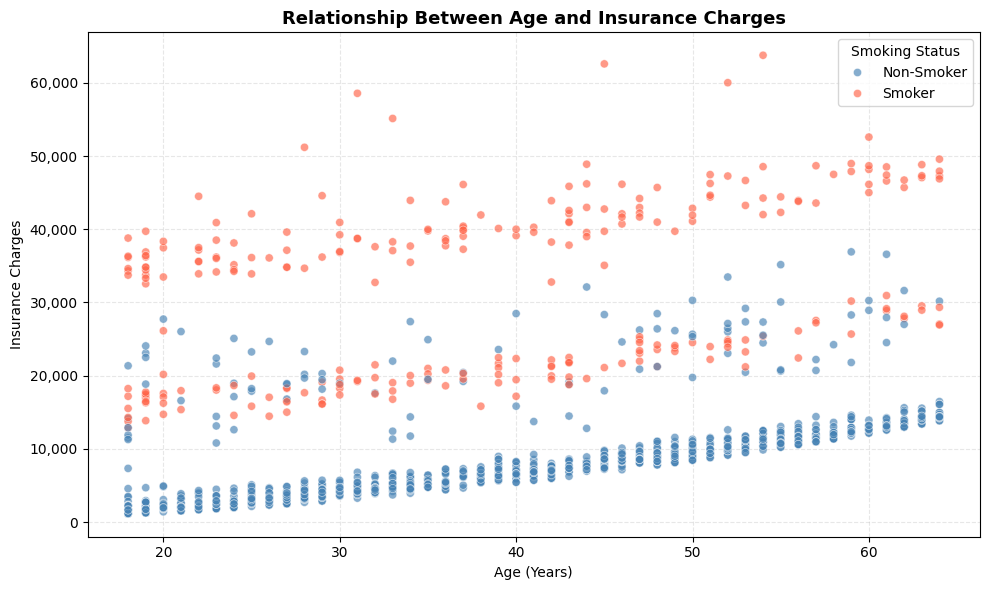

In [26]:

# Visualize the relationship between age and insurance charges
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=insurance_clean_df,
    x="age",
    y="charges",
    hue="smoker",
    hue_order=["no", "yes"],
    palette={"no": "steelblue", "yes": "tomato"},
    alpha=0.65,
    s=35,
    ax=ax
)

# Add descriptive title and labels
ax.set_title(
    "Relationship Between Age and Insurance Charges",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Age (Years)")
ax.set_ylabel("Insurance Charges")

# Format insurance charge values
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Format legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    ["Non-Smoker", "Smoker"],
    title="Smoking Status"
)

# Improve chart readability
ax.grid(linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 6.7.1 Age and Insurance Charges — Findings

The scatterplot reveals a positive association between age and medical insurance charges, with noticeable differences between smokers and non-smokers.

**Key Findings:**

1. **Age Relationship:** Insurance charges generally increase with age. This pattern is particularly visible among non-smokers, whose lower-cost observations form an upward trend.

2. **Smoking Status:** Smokers frequently have substantially higher insurance charges than non-smokers of similar ages.

3. **Variation Among Smokers:** Smoking-related observations are distributed across multiple charge ranges, suggesting that additional factors contribute to insurance costs.

4. **High-Cost Observations:** Several smokers have charges exceeding 50,000, while most non-smokers have considerably lower charges.

5. **Potential Model Limitations:** The different patterns among smokers and non-smokers suggest that an additive Linear Regression model may not fully capture interactions or non-linear relationships between predictors.

**Interpretation:**

Age and smoking status appear to be informative predictors of insurance charges. However, the scatterplot demonstrates associations rather than causal effects.

**Conclusion:**

Both age and smoking status will be retained as predictors in the Linear Regression model. Further analysis will examine BMI to better understand how health-related characteristics are associated with insurance costs.



### 6.8 Relationship Between BMI and Insurance Charges

Body Mass Index (BMI) is a numerical feature that may be associated with medical insurance costs.

A scatterplot is used to investigate the relationship between BMI and insurance charges, with different colors representing smoking status.

This analysis aims to determine:

1. Whether higher BMI values are associated with increased insurance charges.
2. Whether smokers and non-smokers exhibit different BMI-related cost patterns.
3. Whether the relationship appears approximately linear or shows possible interactions.
4. Whether BMI should be retained as a predictor in the Linear Regression model.

The visualization is exploratory and does not establish causal relationships.


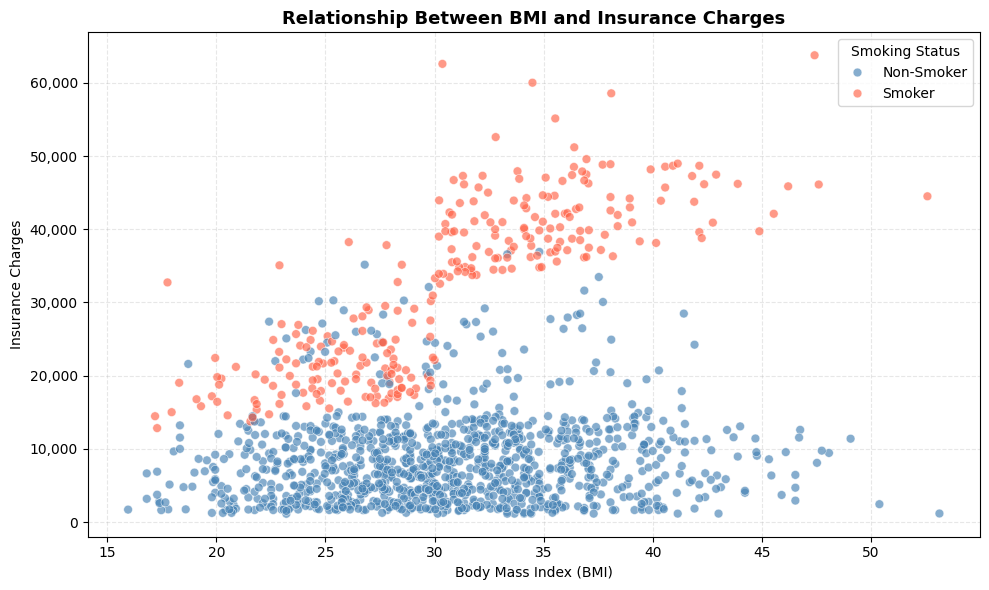

In [27]:

# Visualize the relationship between BMI and insurance charges
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=insurance_clean_df,
    x="bmi",
    y="charges",
    hue="smoker",
    hue_order=["no", "yes"],
    palette={"no": "steelblue", "yes": "tomato"},
    alpha=0.65,
    s=40,
    ax=ax
)

# Add descriptive title and axis labels
ax.set_title(
    "Relationship Between BMI and Insurance Charges",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Body Mass Index (BMI)")
ax.set_ylabel("Insurance Charges")

# Format insurance charges with thousands separators
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Format legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    ["Non-Smoker", "Smoker"],
    title="Smoking Status"
)

# Improve readability
ax.grid(linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 6.8.1 BMI and Insurance Charges — Findings

The scatterplot illustrates the relationship between Body Mass Index (BMI) and medical insurance charges, with observations distinguished by smoking status.

**Key Findings:**

1. **Non-Smokers:** Most non-smokers have relatively lower insurance charges across a wide range of BMI values. No strong positive linear relationship between BMI and charges is visually apparent within this group.

2. **Smokers:** Smoking-related insurance charges show a more noticeable relationship with BMI. Many smokers with BMI values of approximately 30 or higher have charges between 30,000 and 50,000.

3. **Potential Interaction:** The relationship between BMI and insurance charges appears to differ by smoking status. This suggests a possible interaction between the two predictors.

4. **High-Cost Observations:** Several smokers have insurance charges exceeding 50,000, while most non-smokers remain below substantially lower charge levels.

5. **Modeling Implications:** A basic additive Linear Regression model may not fully capture the different BMI-related cost patterns observed among smokers and non-smokers.

**Interpretation:**

The visualization suggests that BMI may provide useful predictive information, particularly when considered together with smoking status. However, the scatterplot alone cannot establish the statistical significance or causality of these relationships.

**Conclusion:**

BMI and smoking status will both be retained as predictors in the Linear Regression model. The baseline model will follow the required algorithm without introducing additional interaction terms initially.

Model performance and residual analysis will help determine whether important patterns remain unexplained by the linear model.



### 6.9 Correlation Analysis of Insurance Features

Pearson correlation analysis is used to examine linear relationships among numerical variables and medical insurance charges.

The analysis includes:

- `age`
- `bmi`
- `children`
- `charges`
- `smoker_yes` (temporary binary indicator: 0 = non-smoker, 1 = smoker)

Pearson correlation coefficients range from -1 to +1, where values closer to either extreme indicate stronger linear associations.

A correlation matrix and heatmap will be used to identify notable relationships between predictors and insurance charges.

**Important Considerations:**

- Correlation does not establish causation.
- The smoking indicator is created only for exploratory analysis.
- The original categorical columns remain unchanged.
- Categorical encoding for model training will be performed separately using an appropriate preprocessing workflow.
- Correlations calculated from the full dataset will not be used for feature selection or model tuning.

All original predictor variables will be retained for the initial Linear Regression model.


Insurance Feature Correlation Matrix:


,age,bmi,children,charges,smoker_yes
age,1.0000,0.1093,0.0415,0.2983,-0.0256
bmi,0.1093,1.0000,0.0128,0.1984,0.0037
children,0.0415,0.0128,1.0000,0.0674,0.0073
charges,0.2983,0.1984,0.0674,1.0000,0.7872
smoker_yes,-0.0256,0.0037,0.0073,0.7872,1.0000



Correlations with Insurance Charges:


,Pearson Correlation
smoker_yes,0.7872
age,0.2983
bmi,0.1984
children,0.0674


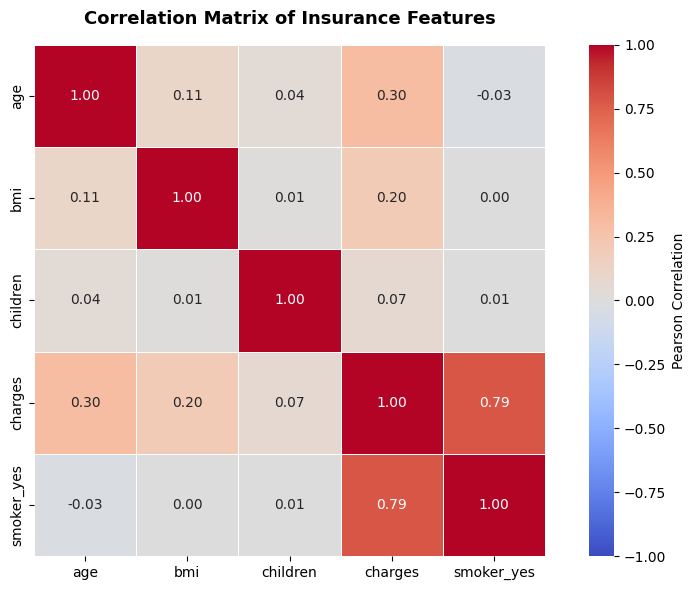

In [28]:

# Prepare numerical variables for correlation analysis
insurance_corr_df = insurance_clean_df[
    ["age", "bmi", "children", "charges"]
].copy()

# Create a temporary numerical smoking indicator
insurance_corr_df["smoker_yes"] = (
    insurance_clean_df["smoker"] == "yes"
).astype(int)

# Calculate the Pearson correlation matrix
insurance_corr_matrix = insurance_corr_df.corr()

print("Insurance Feature Correlation Matrix:")
display(insurance_corr_matrix.round(4))

# Examine correlations with insurance charges
charges_correlations = (
    insurance_corr_matrix["charges"]
    .drop("charges")
    .sort_values(
        key=lambda values: values.abs(),
        ascending=False
    )
)

print("\nCorrelations with Insurance Charges:")
display(
    charges_correlations
    .to_frame(name="Pearson Correlation")
    .round(4)
)

# Visualize correlations using a heatmap
fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    insurance_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title(
    "Correlation Matrix of Insurance Features",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.show()



#### 6.9.1 Correlation Analysis Findings

The Pearson correlation analysis examined relationships between insurance charges and the numerical predictors, including a temporary binary indicator for smoking status.

**Key Findings:**

1. **Smoking Status (r = 0.7872):** Smoking status has the strongest positive correlation with insurance charges. This supports the earlier descriptive analysis showing substantially higher average charges among smokers.

2. **Age (r = 0.2983):** Age exhibits a positive linear association with insurance charges, indicating that older individuals generally tend to have higher charges.

3. **BMI (r = 0.1984):** BMI shows a relatively weak positive linear association with insurance charges. The previous scatterplot suggests that the BMI-related pattern may differ according to smoking status.

4. **Children (r = 0.0674):** The number of children has a very weak positive linear relationship with insurance charges when considered individually.

5. **Relationships Between Predictors:** The numerical predictors have relatively low pairwise correlations with one another in this analysis. However, this does not establish the absence of all multicollinearity or non-linear interactions.

**Interpretation:**

Smoking status appears to be the most informative individual feature among the variables included in this correlation analysis.

However, Pearson correlation measures linear association and does not establish causation or fully describe the predictive contribution of variables in a multivariate model.

Categorical variables such as sex and region were not included in the correlation matrix, but they will be retained in the Linear Regression model.

**Modeling Decision:**

All six original predictors (`age`, `sex`, `bmi`, `children`, `smoker`, and `region`) will be retained for initial model development.

The full-dataset correlations are used only for exploratory analysis, not for selecting or removing model features.

**Conclusion:**

The exploratory analysis identifies smoking status, age, and BMI as potentially informative predictors of medical insurance charges.

The next stage will use a 70/30 train-test split and appropriate categorical encoding to develop the Linear Regression model.



### 6.10 Train-Test Split (70/30)

The cleaned insurance dataset is divided into training and testing subsets using scikit-learn's `train_test_split()` function.

**Dataset Preparation:**

- **Predictor Variables (X):** `age`, `sex`, `bmi`, `children`, `smoker`, and `region`.
- **Target Variable (y):** `charges`.
- **Training Set (70%):** Used to train the Linear Regression model.
- **Testing Set (30%):** Reserved for evaluating predictions on unseen observations.
- **Random State:** 42, ensuring reproducible results.

Unlike the credit card fraud classification problem, insurance cost prediction is a regression task with a continuous target variable.

Therefore, standard random splitting is used without stratifying by target values.

**Data Leakage Prevention:**

The target variable is excluded from the predictor dataset. Categorical encoding and any other fitted preprocessing transformations will be learned exclusively from the training data.

The testing dataset will remain separate until final model evaluation.


In [29]:

from sklearn.model_selection import train_test_split

# Separate the predictors and target variable
X_insurance = insurance_clean_df.drop(columns=["charges"])
y_insurance = insurance_clean_df["charges"]

# Split the dataset into 70% training and 30% testing
X_insurance_train, X_insurance_test, y_insurance_train, y_insurance_test = train_test_split(
    X_insurance,
    y_insurance,
    test_size=0.30,
    random_state=42
)

# Display dataset dimensions
print("Insurance Train-Test Split")
print("-" * 40)

print("Training Features:", X_insurance_train.shape)
print("Testing Features:", X_insurance_test.shape)

print("\nTraining Target:", y_insurance_train.shape)
print("Testing Target:", y_insurance_test.shape)

# Verify the split proportions
total_records = len(insurance_clean_df)

print(
    f"\nTraining Percentage: "
    f"{len(X_insurance_train) / total_records * 100:.2f}%"
)

print(
    f"Testing Percentage: "
    f"{len(X_insurance_test) / total_records * 100:.2f}%"
)

# Verify that the target is excluded from predictors
print(
    "\nTarget Leakage Check:",
    "charges" not in X_insurance_train.columns
    and "charges" not in X_insurance_test.columns
)

# Verify that the training and testing indexes do not overlap
print(
    "Overlapping Row Indexes:",
    len(X_insurance_train.index.intersection(X_insurance_test.index))
)


Insurance Train-Test Split
----------------------------------------
Training Features: (935, 6)
Testing Features: (402, 6)

Training Target: (935,)
Testing Target: (402,)

Training Percentage: 69.93%
Testing Percentage: 30.07%

Target Leakage Check: True
Overlapping Row Indexes: 0



#### 6.10.1 Train-Test Split Findings

The cleaned insurance dataset was successfully divided into training and testing subsets.

**Key Findings:**

1. The training dataset contains 935 observations (69.93%).
2. The testing dataset contains 402 observations (30.07%).
3. Both subsets contain six predictor features.
4. The target variable `charges` was successfully excluded from the predictor datasets.
5. No overlapping row indexes were detected between the training and testing subsets.
6. A fixed random state of 42 ensures reproducibility.

**Conclusion:**

The 70/30 train-test split was completed successfully. The training data will be used for fitting preprocessing transformations and the Linear Regression model, while the testing data will be reserved for final evaluation.



### 6.11 Categorical Feature Encoding

Linear Regression requires numerical input features. Therefore, the categorical predictors `sex`, `smoker`, and `region` must be converted into numerical representations.

**Preprocessing Strategy:**

1. **OneHotEncoder:** Converts categorical values into binary indicator columns.
2. **ColumnTransformer:** Applies one-hot encoding to categorical features while retaining numerical features.
3. **Drop First Category:** Uses `drop="first"` to avoid redundant dummy variables when the model includes an intercept.
4. **Unknown Categories:** Uses `handle_unknown="ignore"` to prevent errors if the testing data contains an unseen category.
5. **Data Leakage Prevention:** The encoder is fitted exclusively on training data and then applied to testing data.

**Numerical Features Retained:**

- `age`
- `bmi`
- `children`

**Categorical Features Encoded:**

- `sex`
- `smoker`
- `region`

The preprocessing process is expected to produce eight numerical predictor columns.

The target variable `charges` remains unchanged.

Numerical standardization is not required for ordinary least squares Linear Regression in this lab, so the numerical predictors will be retained in their original units.


In [30]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define categorical and numerical predictor columns
categorical_features = ["sex", "smoker", "region"]
numerical_features = ["age", "bmi", "children"]

# Create the preprocessing transformer
insurance_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Fit preprocessing only on the training dataset
X_insurance_train_encoded = insurance_preprocessor.fit_transform(
    X_insurance_train
)

# Apply the fitted preprocessing to the testing dataset
X_insurance_test_encoded = insurance_preprocessor.transform(
    X_insurance_test
)

# Retrieve the transformed feature names
insurance_feature_names = (
    insurance_preprocessor.get_feature_names_out()
)

# Verify the transformed dataset shapes
print("Encoded Training Shape:", X_insurance_train_encoded.shape)
print("Encoded Testing Shape:", X_insurance_test_encoded.shape)

print("\nEncoded Feature Names:")
print(insurance_feature_names.tolist())

# Display a sample of the encoded training features
encoded_sample = pd.DataFrame(
    X_insurance_train_encoded,
    columns=insurance_feature_names,
    index=X_insurance_train.index
)

print("\nFirst Five Encoded Training Records:")
display(encoded_sample.head())

# Verify that preprocessing did not introduce missing values
print(
    "\nMissing Values After Encoding:",
    np.isnan(X_insurance_train_encoded).sum()
    + np.isnan(X_insurance_test_encoded).sum()
)


Encoded Training Shape: (935, 8)
Encoded Testing Shape: (402, 8)

Encoded Feature Names:
['sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'age', 'bmi', 'children']

First Five Encoded Training Records:


,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,age,bmi,children
138,0.0,0.0,0.0,1.0,0.0,54.0,31.900,3.0
381,1.0,1.0,0.0,0.0,0.0,55.0,30.685,0.0
292,1.0,1.0,0.0,1.0,0.0,25.0,45.540,2.0
1089,1.0,1.0,0.0,1.0,0.0,47.0,36.190,0.0
892,1.0,1.0,0.0,1.0,0.0,47.0,38.940,2.0



Missing Values After Encoding: 0



#### 6.11.1 Categorical Encoding Findings

The categorical preprocessing was completed successfully using OneHotEncoder and ColumnTransformer.

**Key Findings:**

1. The original six predictors were transformed into eight numerical features.
2. The encoded training dataset contains 935 observations and 8 features.
3. The encoded testing dataset contains 402 observations and 8 features.
4. One-hot encoding created binary indicator columns for sex, smoking status, and region.
5. Numerical predictors (`age`, `bmi`, and `children`) were retained in their original units.
6. No missing values were introduced during encoding.
7. The preprocessing transformer was fitted exclusively on training data to prevent data leakage.

**Reference Categories:**

The first category of each categorical feature was dropped to prevent redundant dummy variables in the regression model.

- `sex`: female
- `smoker`: no
- `region`: northeast

**Conclusion:**

All predictor features have been converted into a numerical format suitable for Linear Regression. The processed datasets are now ready for model training and evaluation.



### 6.12 Linear Regression Model Training

Linear Regression is a supervised learning algorithm used to predict continuous numerical values.

In this lab, the model estimates medical insurance charges based on six original predictor variables, represented by eight numerical features after categorical encoding.

The model follows the general multiple linear regression equation:

$$
\hat{y} = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_nx_n
$$

Where:

- $\hat{y}$ represents the predicted insurance charges.
- $\beta_0$ represents the intercept.
- $\beta_1, \beta_2, \ldots, \beta_n$ represent regression coefficients.
- $x_1, x_2, \ldots, x_n$ represent the predictor feature values.

**Model Configuration:**

- **Algorithm:** Linear Regression
- **Implementation:** scikit-learn
- **Training observations:** 935
- **Encoded predictor features:** 8
- **Intercept:** Enabled (default)
- **Training method:** Ordinary Least Squares

The model minimizes the sum of squared differences between actual and predicted insurance charges.

Only the training dataset is used to estimate the regression coefficients. The testing dataset remains reserved for final performance evaluation.


In [31]:

from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
insurance_lr_model = LinearRegression()

# Train the model using encoded training features
insurance_lr_model.fit(
    X_insurance_train_encoded,
    y_insurance_train
)

# Verify successful model training
print("Linear Regression Model Trained Successfully!")
print("-" * 45)

print("Algorithm: Linear Regression")
print("Training Observations:", X_insurance_train_encoded.shape[0])
print("Number of Features:", insurance_lr_model.n_features_in_)
print(f"Model Intercept: {insurance_lr_model.intercept_:,.4f}")

# Create a table of learned regression coefficients
insurance_coefficients = pd.DataFrame({
    "Feature": insurance_feature_names,
    "Coefficient": insurance_lr_model.coef_
})

# Sort coefficients by value for readability
insurance_coefficients = (
    insurance_coefficients
    .sort_values(by="Coefficient", ascending=False)
    .reset_index(drop=True)
)

print("\nLearned Regression Coefficients:")
display(insurance_coefficients.round(4))


Linear Regression Model Trained Successfully!
---------------------------------------------
Algorithm: Linear Regression
Training Observations: 935
Number of Features: 8
Model Intercept: -11,516.7810

Learned Regression Coefficients:


,Feature,Coefficient
0,smoker_yes,22874.4464
1,children,522.1554
2,bmi,328.3831
3,age,251.2462
4,sex_male,-111.9072
5,region_northwest,-465.7466
6,region_southwest,-765.5839
7,region_southeast,-936.0993



#### 6.12.1 Linear Regression Training Findings

The multiple Linear Regression model was successfully trained using 935 observations and eight encoded predictor features.

**Model Intercept:** -11,516.7810

**Key Coefficient Findings:**

1. **Smoking Status (+22,874.45):** Holding other predictors constant, smokers are predicted to have insurance charges approximately 22,874.45 units higher than non-smokers.

2. **Age (+251.25):** Each additional year of age is associated with an estimated increase of approximately 251.25 units in predicted insurance charges, assuming other predictors remain constant.

3. **BMI (+328.38):** A one-unit increase in BMI is associated with approximately 328.38 units higher predicted charges, holding other variables constant.

4. **Children (+522.16):** Each additional child is associated with an estimated increase of approximately 522.16 units in predicted charges.

5. **Sex (-111.91):** The coefficient for males indicates slightly lower predicted charges relative to females, after accounting for other included predictors.

6. **Region:** The northwest, southwest, and southeast indicators have negative coefficients relative to the reference category, northeast.

**Interpretation:**

Smoking status has the largest numerical coefficient among the encoded binary predictors and is associated with a substantial difference in predicted insurance charges.

However, raw coefficient magnitudes cannot be compared directly across all features because numerical predictors have different units and scales.

The negative intercept represents a mathematical baseline where all encoded predictors equal zero. Since this includes unrealistic values such as age zero and BMI zero, the intercept should not be interpreted as a realistic insurance charge.

The coefficients describe associations learned from the training data and do not establish causation or statistical significance.

**Conclusion:**

The Linear Regression model has successfully learned relationships between demographic and lifestyle predictors and medical insurance charges.

The next step is to evaluate its predictive performance on the independent testing dataset using appropriate regression metrics.



### 6.13 Linear Regression Model Evaluation

The trained Linear Regression model is evaluated on the independent 30% testing dataset containing 402 observations.

Four regression metrics are calculated:

1. **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted insurance charges.

2. **Mean Squared Error (MSE):** Measures the average squared prediction error and places greater emphasis on large errors.

3. **Root Mean Squared Error (RMSE):** Expresses prediction error in the same units as insurance charges while penalizing large errors.

4. **Coefficient of Determination (R²):** Measures how much variation in insurance charges is explained by the model relative to predicting a constant mean. An R² value of 1 indicates perfect predictions, while negative values indicate performance worse than the constant-mean baseline.

Both training and testing metrics will be examined to assess generalization.

A simple baseline that predicts the mean insurance charge from the training dataset will also be evaluated.

Because this is a regression problem, classification accuracy is not an appropriate metric. Instead, prediction accuracy is assessed through regression errors and R².


In [32]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Generate predictions for training and testing datasets
y_insurance_train_pred = insurance_lr_model.predict(
    X_insurance_train_encoded
)

y_insurance_pred = insurance_lr_model.predict(
    X_insurance_test_encoded
)

# Define a helper function to calculate regression metrics
def calculate_regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

# Evaluate training and testing performance
train_metrics = calculate_regression_metrics(
    y_insurance_train, y_insurance_train_pred
)

test_metrics = calculate_regression_metrics(
    y_insurance_test, y_insurance_pred
)

# Create a baseline using the training target mean
baseline_predictions = np.full(
    len(y_insurance_test),
    y_insurance_train.mean()
)

baseline_metrics = calculate_regression_metrics(
    y_insurance_test, baseline_predictions
)

# Compare regression performance
insurance_evaluation = pd.DataFrame({
    "Training": train_metrics,
    "Testing": test_metrics,
    "Mean Baseline (Test)": baseline_metrics
}).T

print("Linear Regression Performance Evaluation:")
display(insurance_evaluation.round(4))

# Display sample predictions from the test dataset
prediction_comparison = pd.DataFrame({
    "Actual Charges": y_insurance_test.to_numpy(),
    "Predicted Charges": y_insurance_pred,
    "Absolute Error": np.abs(
        y_insurance_test.to_numpy() - y_insurance_pred
    )
}, index=y_insurance_test.index)

print("\nSample Predictions (First 10 Test Records):")
display(prediction_comparison.head(10).round(2))


Linear Regression Performance Evaluation:


,MAE,MSE,RMSE,R2
Training,4165.8309,3.581293e+07,5984.3908,0.7363
Testing,4181.8160,3.894017e+07,6240.2059,0.7724
Mean Baseline (Test),9423.6573,1.717766e+08,13106.3558,-0.0039



Sample Predictions (First 10 Test Records):


,Actual Charges,Predicted Charges,Absolute Error
899,8688.86,8075.92,612.94
1063,5708.87,5499.00,209.86
1255,11436.74,14345.71,2908.97
298,38746.36,31428.20,7318.15
237,4463.21,8874.78,4411.58
481,9304.70,13108.24,3803.53
240,38511.63,30222.45,8289.18
277,2150.47,1224.76,925.71
415,7345.73,10576.43,3230.71
706,10264.44,11204.40,939.96



#### 6.13.1 Linear Regression Evaluation Findings

The Linear Regression model was evaluated using 402 unseen testing observations.

**Performance Results:**

| Metric | Training | Testing | Mean Baseline (Test) |
|---|---:|---:|---:|
| MAE | 4,165.83 | 4,181.82 | 9,423.66 |
| RMSE | 5,984.39 | 6,240.21 | 13,106.36 |
| R² | 0.7363 | 0.7724 | -0.0039 |

**Key Findings:**

1. **Mean Absolute Error (MAE):** The testing MAE of 4,181.82 indicates that the model's predictions differ from actual insurance charges by approximately 4,182 units on average in absolute terms.

2. **Root Mean Squared Error (RMSE):** The testing RMSE of 6,240.21 is higher than MAE because RMSE places greater emphasis on large prediction errors.

3. **Coefficient of Determination (R²):** The testing R² of 0.7724 indicates that the model explains approximately 77.24% of the variation in insurance charges in the testing dataset.

4. **Training and Testing Performance:** The training R² is 0.7363, compared with 0.7724 for testing. The relatively similar prediction errors provide no obvious evidence of severe overfitting, although performance may vary across different data splits.

5. **Baseline Comparison:** The constant-mean baseline produced a testing MAE of 9,423.66 and RMSE of 13,106.36. Linear Regression reduced MAE by approximately 55.6% compared with this baseline.

6. **Individual Predictions:** The sample predictions demonstrate that errors vary across observations. Some predictions are close to actual charges, while others have considerably larger absolute differences.

**Interpretation:**

The Linear Regression model substantially outperforms the simple mean-prediction baseline and captures a meaningful proportion of the variation in insurance charges.

However, an R² of 0.7724 also indicates that some variation remains unexplained by the model.

**Conclusion:**

The model provides a useful baseline for predicting insurance charges. Further diagnostic analysis is needed to investigate prediction patterns, large errors, and potential limitations of the additive linear relationship.



### 6.14 Actual vs. Predicted Insurance Charges

A scatterplot is used to compare the model's predicted insurance charges with the actual charges in the testing dataset.

The visualization includes a diagonal reference line representing perfect predictions, where the predicted value equals the actual value.

**Interpretation:**

- Points close to the diagonal line represent more accurate predictions.
- Points above the line represent overpredictions.
- Points below the line represent underpredictions.
- Greater distances from the line indicate larger prediction errors.

The objective is to assess whether prediction errors are evenly distributed or whether systematic patterns are present across different insurance charge levels.


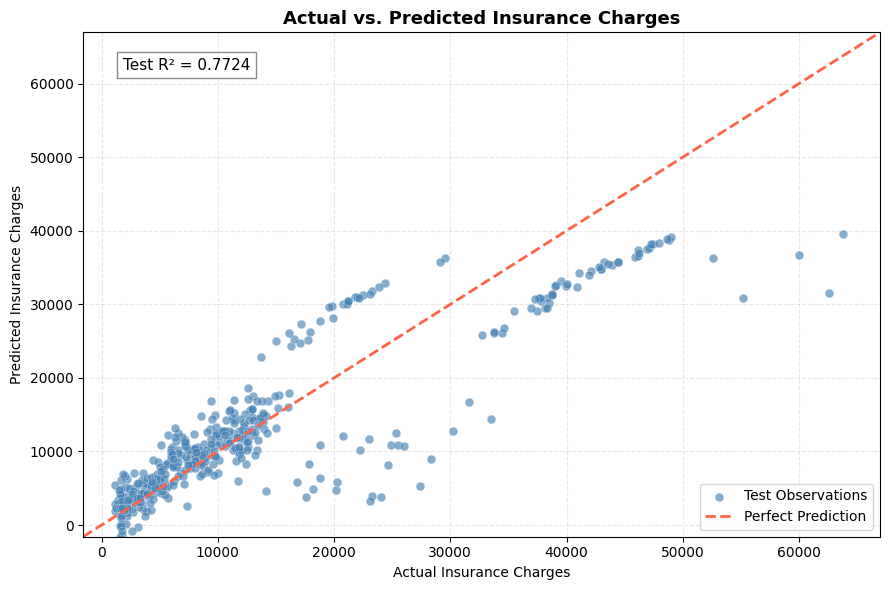

In [33]:

# Create an actual versus predicted scatterplot
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    y_insurance_test,
    y_insurance_pred,
    color="steelblue",
    alpha=0.65,
    s=40,
    edgecolors="white",
    linewidths=0.3,
    label="Test Observations"
)

# Determine common limits for a fair comparison
all_values = np.concatenate([
    y_insurance_test.to_numpy(),
    y_insurance_pred
])

plot_min = min(0, all_values.min())
plot_max = all_values.max() * 1.05

# Add the perfect prediction reference line
ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color="tomato",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

# Use identical scales on both axes
ax.set_xlim(plot_min, plot_max)
ax.set_ylim(plot_min, plot_max)

# Add descriptive labels
ax.set_title(
    "Actual vs. Predicted Insurance Charges",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Actual Insurance Charges")
ax.set_ylabel("Predicted Insurance Charges")

# Display the model R² score
ax.text(
    0.05,
    0.95,
    f"Test R² = {test_metrics['R2']:.4f}",
    transform=ax.transAxes,
    fontsize=11,
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

# Improve readability
ax.legend(loc="lower right")
ax.grid(linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 6.14.1 Actual vs. Predicted Charges — Findings

The scatterplot compares actual insurance charges with predictions generated by the Linear Regression model on the 402 testing observations.

**Key Findings:**

1. **Overall Predictive Performance:** The model achieved a testing R² of 0.7724, indicating that approximately 77.24% of the variation in testing insurance charges is explained by the model relative to the constant-mean reference.

2. **Lower Insurance Charges:** Many lower-cost observations fall relatively close to the perfect prediction line, indicating smaller prediction errors for these cases.

3. **High-Cost Underprediction:** Several individuals with actual charges exceeding approximately 35,000 have substantially lower predicted values. This suggests the model has difficulty estimating some expensive insurance cases.

4. **Middle-Range Variation:** Observations in the middle charge ranges appear on both sides of the reference line, indicating both overprediction and underprediction.

5. **Visible Prediction Patterns:** The scatterplot shows distinct groups and systematic deviations from the perfect prediction line. These patterns suggest that the additive Linear Regression model may not fully capture interactions or non-linear relationships among the predictors.

6. **Model Limitations:** The predictions demonstrate that a relatively strong R² score does not guarantee accurate predictions for every individual.

**Conclusion:**

The Linear Regression model provides useful insurance cost estimates but shows notable prediction errors for certain observations, particularly some high-cost cases.

Residual analysis will be conducted to investigate the direction, magnitude, and distribution of prediction errors more carefully.



### 6.15 Residual Analysis

Residual analysis is used to examine the differences between actual and predicted insurance charges.

A residual is calculated as:

$$
e_i = y_i - \hat{y}_i
$$

Where:
- $e_i$ represents the residual.
- $y_i$ represents the actual insurance charge.
- $\hat{y}_i$ represents the predicted insurance charge.

**Interpretation:**

- **Positive residual:** The model underestimated insurance charges.
- **Negative residual:** The model overestimated insurance charges.
- **Zero residual:** The predicted value matches the actual value.

A residual scatterplot will be created using predicted insurance charges on the horizontal axis and residuals on the vertical axis.

The analysis will investigate whether prediction errors are randomly distributed around zero or exhibit systematic patterns, changing variability, or unusually large deviations.

The number of negative predictions will also be checked because negative insurance charges are not meaningful in practice.


Insurance Model Residual Analysis
---------------------------------------------
Mean Residual: 739.99
Median Residual: -726.43
Minimum Residual: -10,204.12
Maximum Residual: 31,007.43
Residual Standard Deviation: 6,196.17

Negative Insurance Charge Predictions: 7


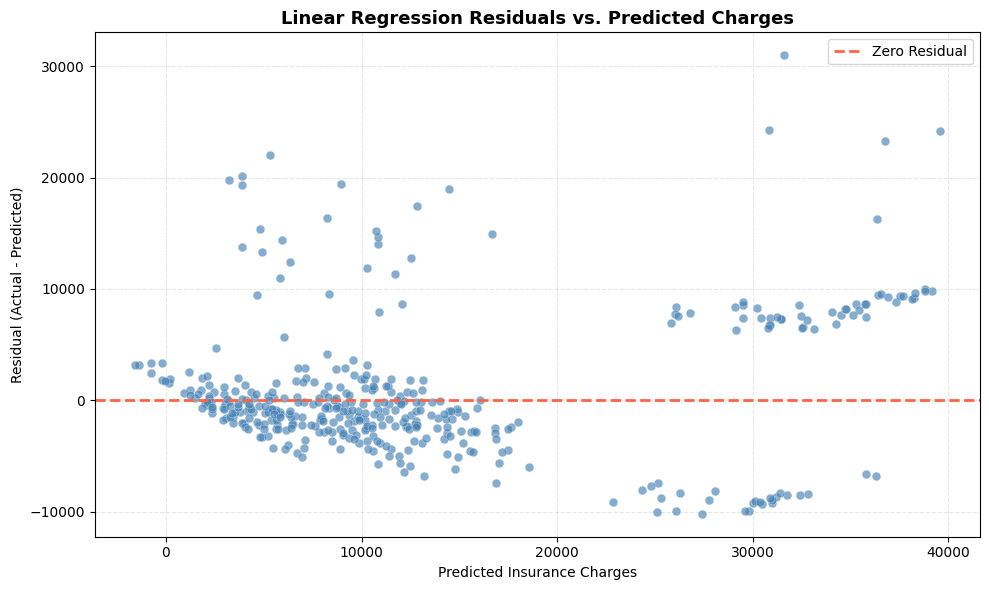

In [34]:

# Calculate residuals on the testing dataset
insurance_residuals = (
    y_insurance_test.to_numpy() - y_insurance_pred
)

# Display residual summary statistics
print("Insurance Model Residual Analysis")
print("-" * 45)

print(f"Mean Residual: {insurance_residuals.mean():,.2f}")
print(f"Median Residual: {np.median(insurance_residuals):,.2f}")
print(f"Minimum Residual: {insurance_residuals.min():,.2f}")
print(f"Maximum Residual: {insurance_residuals.max():,.2f}")
print(f"Residual Standard Deviation: {insurance_residuals.std():,.2f}")

# Check for negative predictions
negative_prediction_count = np.sum(y_insurance_pred < 0)

print(
    f"\nNegative Insurance Charge Predictions: "
    f"{negative_prediction_count}"
)

# Create a residuals vs. predicted values scatterplot
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    y_insurance_pred,
    insurance_residuals,
    color="steelblue",
    alpha=0.65,
    s=40,
    edgecolors="white",
    linewidths=0.3
)

# Add horizontal reference line at zero residual
ax.axhline(
    y=0,
    color="tomato",
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

# Add descriptive title and labels
ax.set_title(
    "Linear Regression Residuals vs. Predicted Charges",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Predicted Insurance Charges")
ax.set_ylabel("Residual (Actual - Predicted)")

# Improve chart readability
ax.legend()
ax.grid(linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 6.15.1 Residual Analysis Findings

Residual analysis was performed on the 402 test observations to investigate the errors produced by the Linear Regression model.

**Residual Summary:**

| Statistic | Value |
|---|---:|
| Mean Residual | 739.99 |
| Median Residual | -726.43 |
| Minimum Residual | -10,204.12 |
| Maximum Residual | 31,007.43 |
| Residual Standard Deviation | 6,196.17 |
| Negative Charge Predictions | 7 |

**Key Findings:**

1. **Mean Residual:** The mean residual is positive (739.99), indicating that the model underpredicts insurance charges on average across the testing dataset.

2. **Median Residual:** The median residual is negative (-726.43), suggesting that overprediction occurs for at least half of the test observations. The difference between the mean and median reflects the influence of larger positive residuals.

3. **Large Prediction Errors:** The maximum positive residual is 31,007.43, indicating substantial underprediction for at least one observation. The minimum residual of -10,204.12 represents a substantial overprediction.

4. **Systematic Residual Patterns:** The residual scatterplot displays distinct groups and non-random patterns, suggesting that the additive Linear Regression model does not fully capture the relationships between predictors and insurance charges.

5. **Non-Constant Error Variation:** The residual spread differs across predicted charge levels. This suggests possible heteroscedasticity, although the visualization alone is insufficient to establish a formal statistical conclusion.

6. **Negative Predictions:** The model generated seven negative insurance charge predictions, representing approximately 1.74% of the test observations. Negative insurance charges are not practically meaningful and illustrate a limitation of unconstrained Linear Regression.

**Interpretation:**

Although the model achieves a testing R² of 0.7724, the residual analysis reveals systematic prediction errors and substantial deviations for certain observations.

The earlier exploratory analysis suggested possible interactions between BMI and smoking status, which may help explain some of the unexplained variation.

However, additional modeling would be required to determine whether incorporating interaction terms or non-linear relationships improves predictive performance.

**Conclusion:**

The residual analysis demonstrates that Linear Regression provides a useful baseline but does not fully capture the complexity of insurance charges.

The model's limitations include large individual prediction errors, possible non-constant error variance, systematic residual patterns, and occasional negative predictions.

These findings should be considered when interpreting the model's predictions and assessing its suitability for practical applications.



### 6.16 Distribution of Regression Residuals

A histogram with a Kernel Density Estimate (KDE) is used to examine the distribution of residuals from the Linear Regression model.

The visualization includes reference lines for zero residual and the mean residual.

The analysis aims to investigate:

1. Whether residuals are approximately symmetric around zero.
2. Whether the distribution contains substantial positive or negative tails.
3. Whether unusually large errors influence the residual distribution.
4. Whether the residual distribution suggests potential departures from normality.

This exploratory visualization complements the residual scatterplot.

A residual histogram alone cannot establish that all Linear Regression assumptions are satisfied. In particular, it does not assess independence or constant error variance.


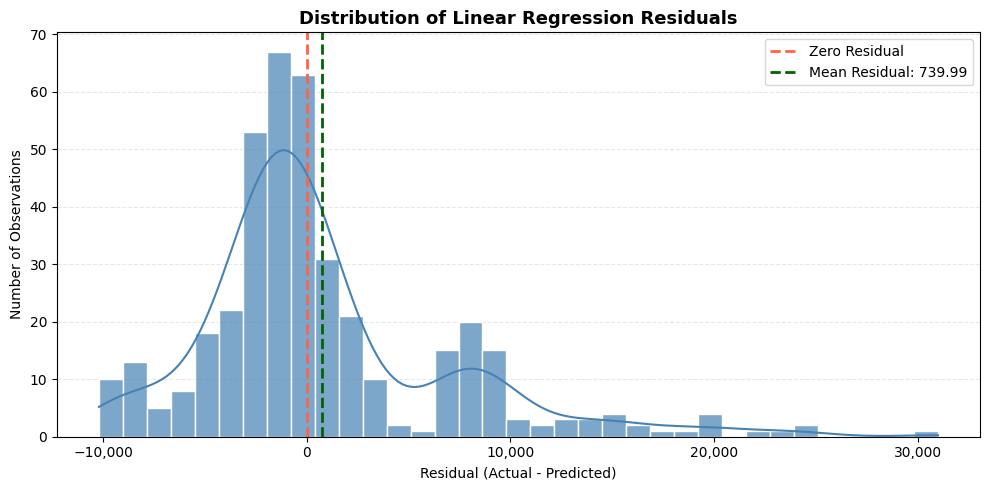

In [35]:

# Create the residual distribution visualization
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    insurance_residuals,
    bins=35,
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.7,
    ax=ax
)

# Add reference line for perfect prediction
ax.axvline(
    0,
    color="tomato",
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

# Add reference line for mean residual
ax.axvline(
    insurance_residuals.mean(),
    color="darkgreen",
    linestyle="--",
    linewidth=2,
    label=f"Mean Residual: {insurance_residuals.mean():,.2f}"
)

# Add descriptive labels
ax.set_title(
    "Distribution of Linear Regression Residuals",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Residual (Actual - Predicted)")
ax.set_ylabel("Number of Observations")

# Format residual values
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Improve readability
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 6.16.1 Residual Distribution Findings

The residual histogram and Kernel Density Estimate (KDE) provide additional insight into the prediction errors of the Linear Regression model.

**Key Findings:**

1. **Main Residual Concentration:** Most residuals are concentrated around zero or slightly below zero, indicating that many predictions have relatively small errors or slightly overestimate actual charges.

2. **Positive Skewness:** The residual distribution has a noticeable right tail extending to approximately 31,007.43. This indicates that some insurance charges are substantially underpredicted.

3. **Mean and Median Residuals:** The mean residual is 739.99, while the median is -726.43. The difference suggests that large positive residuals influence the average prediction error.

4. **Distribution Shape:** The histogram is not approximately symmetric or bell-shaped. A secondary concentration of positive residuals is visible around 7,000–10,000.

5. **Potential Model Misspecification:** The observed patterns suggest that the additive Linear Regression model may not fully capture important relationships between insurance charges and the predictors.

6. **Normality Consideration:** The residual distribution visually departs from a normal distribution. However, this visualization alone does not establish the statistical significance of the departure or determine whether all regression assumptions are satisfied.

**Interpretation:**

Although the model explains approximately 77.24% of the variation in testing insurance charges, the residual distribution reveals substantial prediction errors for certain observations.

The earlier exploratory analysis suggested that BMI and smoking status may interact in their relationship with insurance charges. Such interactions could contribute to systematic errors in an additive model.

**Conclusion:**

Residual analysis confirms that Linear Regression provides useful baseline predictions but does not fully represent the complexity of insurance charges.

Potential improvements include evaluating interaction terms, non-linear approaches, or alternative target transformations using training-only validation.

The original Linear Regression model is retained as the primary solution because it fulfills the lab requirements and provides an interpretable baseline.



### 6.17 Part B — Final Conclusion

This part of Lab 3 successfully developed and evaluated a multiple Linear Regression model for predicting medical insurance charges.

#### Data Preparation and Exploratory Analysis

- The original dataset contained 1,338 observations and 7 columns.
- One exact duplicate record was removed, leaving 1,337 observations.
- No missing values were identified.
- The dataset contained three numerical predictors and three categorical predictors.
- Exploratory analysis revealed a positively skewed distribution of insurance charges.
- Smoking status showed the strongest individual linear association with insurance charges (r = 0.7872).
- Smokers had approximately 3.80 times higher average insurance charges than non-smokers.

#### Model Development

The cleaned dataset was divided into 70% training data (935 observations) and 30% testing data (402 observations).

Categorical predictors were transformed using OneHotEncoder, producing eight numerical features.

Preprocessing transformations were fitted exclusively on training data to prevent data leakage.

A multiple Linear Regression model was trained using scikit-learn.

#### Model Evaluation

| Metric | Training | Testing |
|---|---:|---:|
| MAE | 4,165.83 | 4,181.82 |
| RMSE | 5,984.39 | 6,240.21 |
| R² | 0.7363 | 0.7724 |

The testing R² of 0.7724 indicates that the model explains approximately 77.24% of the variation in insurance charges relative to the constant-mean reference.

The testing MAE of 4,181.82 represents the average absolute prediction error.

The model also substantially outperformed the mean-prediction baseline, reducing testing MAE by approximately 55.6%.

#### Key Limitations

1. The model produced seven negative insurance charge predictions, which are not meaningful in practice.
2. Several high-cost insurance observations were substantially underpredicted.
3. Residual plots revealed systematic patterns and possible non-constant error variance.
4. The residual distribution was asymmetric, with a long positive tail.
5. The additive model may not adequately represent non-linear relationships or interactions between BMI and smoking status.
6. Evaluation was based on a single 70/30 train-test split, so performance may vary with different samples.

#### Overall Conclusion

Multiple Linear Regression successfully predicted medical insurance charges using demographic and lifestyle characteristics.

The model achieved a testing R² of 0.7724 and demonstrated substantially better predictive performance than a constant-mean baseline.

Smoking status was strongly associated with insurance charges, while age, BMI, and other predictors also contributed to the model.

However, residual analysis revealed important limitations, particularly for some high-cost observations.

Overall, Linear Regression provides an interpretable and useful baseline for insurance cost prediction, but additional validation and more flexible modeling approaches may be necessary for applications requiring greater predictive reliability.



---

## 7. Overall Lab 3 Findings and Conclusion

### 7.1 Summary of Both Machine Learning Tasks

This lab explored two supervised machine learning approaches using real-world datasets: Logistic Regression for credit card fraud classification and Linear Regression for medical insurance cost prediction.

Both tasks followed a structured machine learning workflow involving data exploration, preprocessing, 70/30 train-test splitting, model training, evaluation, and interpretation.

| Component | Part A — Fraud Detection | Part B — Insurance Prediction |
|---|---|---|
| Learning Task | Binary Classification | Multiple Linear Regression |
| Algorithm | Logistic Regression | Linear Regression |
| Cleaned Observations | 283,726 | 1,337 |
| Training Observations | 198,608 | 935 |
| Testing Observations | 85,118 | 402 |
| Preprocessing | StandardScaler | OneHotEncoder |
| Primary Evaluation | Accuracy, Precision, Recall, F1 | MAE, MSE, RMSE, R² |
| Key Challenge | Severe Class Imbalance | Skewed Charges and Systematic Residual Patterns |

### 7.2 Key Results

**Part A — Credit Card Fraud Detection**

The baseline Logistic Regression model achieved:

- Accuracy: 99.91%
- Fraud Precision: 84.04%
- Fraud Recall: 55.63%
- Fraud F1-Score: 66.95%
- ROC-AUC: 0.9647
- Average Precision: 0.7040

Although the model achieved high overall accuracy, it missed 63 of 142 fraudulent test transactions.

A training-only validation comparison demonstrated that class weighting improved fraud recall but substantially increased false-positive predictions. Standard Logistic Regression was selected based on its higher validation F1-score.

This highlights the importance of evaluating imbalanced classification problems using multiple performance metrics rather than relying on accuracy alone.

**Part B — Insurance Cost Prediction**

The Linear Regression model achieved:

- Testing MAE: 4,181.82
- Testing RMSE: 6,240.21
- Testing R²: 0.7724

The model explained approximately 77.24% of the variation in testing insurance charges and substantially outperformed a constant-mean prediction baseline.

Smoking status demonstrated a strong positive association with insurance charges, while age and BMI also contributed predictive information.

However, residual analysis revealed systematic errors, occasional negative predictions, and substantial underprediction for some high-cost observations.

### 7.3 Important Learning Outcomes

The two tasks demonstrate several essential supervised learning concepts:

1. **Data Preparation:** Missing values, duplicates, data types, and categorical features must be examined before modeling.

2. **Preprocessing:** Feature standardization and categorical encoding should be selected according to the dataset and algorithm.

3. **Data Leakage Prevention:** Fitted preprocessing operations must learn their parameters from training data rather than testing data.

4. **Model Evaluation:** Classification and regression require different evaluation metrics. High classification accuracy does not necessarily indicate effective minority-class detection, while regression performance must be assessed using prediction errors and explained variance.

5. **Model Limitations:** Numerical evaluation scores should be interpreted alongside visualizations, confusion matrices, and residual diagnostics.

6. **Reproducibility:** Fixed random states, documented preprocessing decisions, and saved notebook outputs help make results reproducible.

### 7.4 Limitations and Future Improvements

Both analyses have limitations.

For fraud detection, the extreme class imbalance, relatively small number of fraudulent examples, and reliance on a single validation split create uncertainty about generalization. Although the notebook was subsequently reorganized to present validation before test evaluation, test results were inspected during the original development process.

For insurance prediction, evaluation relied on a single random train-test split, and residual diagnostics suggested that an additive linear model does not capture all relationships in the data.

Future improvements could include:

- Stratified cross-validation and training-only decision-threshold optimization for fraud detection.
- Additional validation of model stability across data splits.
- Investigation of BMI-smoking interaction terms for insurance cost prediction.
- Comparison with more flexible regression approaches when permitted.

These improvements would require independent validation before making claims about improved predictive performance.

### 7.5 Final Conclusion

This lab successfully implemented and evaluated two supervised machine learning algorithms for different prediction tasks.

Logistic Regression demonstrated useful fraud classification performance while revealing the challenges of severe class imbalance and the trade-off between precision and recall.

Linear Regression provided interpretable insurance cost predictions and explained a substantial proportion of the variation in medical charges. However, prediction and residual analyses identified important limitations.

Overall, the lab demonstrates that successful machine learning involves more than training a model. Appropriate preprocessing, careful evaluation, interpretation of results, awareness of model limitations, and reproducibility are essential for developing reliable predictive systems.



---

## 8. References

The following datasets, documentation, and course materials were used to support the implementation and understanding of the machine learning techniques demonstrated in this lab.

### 8.1 Datasets

1. Machine Learning Group, Université Libre de Bruxelles. (n.d.). *Credit Card Fraud Detection* [Dataset]. Kaggle.  
   https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

2. Mirichoi. (n.d.). *Medical Cost Personal Datasets* [Dataset]. Kaggle.  
   https://www.kaggle.com/datasets/mirichoi0218/insurance

### 8.2 Python and Machine Learning Documentation

3. Scikit-learn developers. (n.d.). *LogisticRegression — scikit-learn documentation*.  
   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

4. Scikit-learn developers. (n.d.). *LinearRegression — scikit-learn documentation*.  
   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

5. Scikit-learn developers. (n.d.). *train_test_split — scikit-learn documentation*.  
   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

6. Scikit-learn developers. (n.d.). *Preprocessing and data transformation — scikit-learn documentation*.  
   https://scikit-learn.org/stable/modules/preprocessing.html

7. Scikit-learn developers. (n.d.). *Model evaluation — scikit-learn documentation*.  
   https://scikit-learn.org/stable/modules/model_evaluation.html

### 8.3 Course Materials

8. *Classification Algorithms* — Week 9 lecture materials, Artificial Intelligence Algorithms and Mathematics, Conestoga College.

9. *Statistics 2* — Week 10 lecture materials, Artificial Intelligence Algorithms and Mathematics, Conestoga College.

---

## 9. Reproducibility and Environment Information

### 9.1 Dataset Requirements

The notebook uses two publicly available Kaggle datasets:

- `creditcard.csv` — Credit Card Fraud Detection
- `insurance.csv` — Medical Cost Personal Dataset

Both CSV files must be placed in the same directory as the notebook before execution.

The raw datasets are excluded from the GitHub repository using `.gitignore`. They can be downloaded separately from the original Kaggle sources listed in Section 8.1.

### 9.2 Software Environment

The implementation uses Python and the following libraries:

- pandas
- NumPy
- Matplotlib
- Seaborn
- scikit-learn

The lab was implemented in Python using pandas, NumPy, Matplotlib, Seaborn, and scikit-learn. Jupyter Notebook was used for code execution, analysis, and visualization.

### 9.3 Reproducibility Considerations

The following practices support reproducible results:

1. A fixed `random_state=42` is used for train-test splitting and applicable model configurations.
2. The required 70/30 train-test split is maintained for both datasets.
3. Preprocessing transformations are fitted exclusively on the appropriate training data.
4. Original datasets are preserved separately from cleaned datasets.
5. Model predictions, evaluation metrics, and visualizations are retained as notebook outputs.
6. Data cleaning and model selection decisions are documented alongside their limitations.

The notebook can be executed from beginning to end after installing the required dependencies and placing both CSV files in the project directory.

Model results may vary if the underlying datasets, software implementations, or preprocessing procedures are changed.
